# Q1. Camera

## (a)

### Task:
In Assignment 1, Q1, find the coordinates of the centre of the swinging load, $o_1(x, y, z)$, for all frames in the training set `rgb_train_val_swingingload.avi`. Use the $M_{int}$ obtained in the Lab. Plot the 3D coordinates of the swinging load for all frames.

### Approach:
1. Define the intrinsic matrix $M_{int}$ from the lab.
2. Detect the swinging load in each frame with the YOLO model from Assignment 1 and take the centre pixel $(u, v)$ of the box.
3. Read the depth at $(u, v)$ and remove depth outliers.
4. Use $M_{int}$ to convert $(u, v, depth)$ into 3D camera coordinates $(X, Y, Z)$.
5. Plot the complete 3D trajectory.

In [5]:
# Q1 setup: imports, data folder and YOLO model (Q1 runs independently of Q2-Q4)
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from ultralytics import YOLO

Q1_SESSION = Path("data_assignment1_q1") / "data" / "session_20260918_152400_train"
Q1_SEARCH_ROOTS = [Path.cwd() / Q1_SESSION, Path.cwd() / "MAS512_Group9_data" / Q1_SESSION]
q1_root = next((root for root in Q1_SEARCH_ROOTS if (root / "rgb_frames").is_dir()), None)
if q1_root is None:
    raise FileNotFoundError("Could not find the Assignment 1 training session. Update Q1_SEARCH_ROOTS.")

Q1_MODEL_PATH = Path.cwd() / "YOLO_swinging_load.pt"
if not Q1_MODEL_PATH.is_file():
    raise FileNotFoundError(f"Missing YOLO model: {Q1_MODEL_PATH}")

print("Training session:", q1_root)

Training session: c:\Users\resjw\Downloads\data_assignment1_q1\data\session_20260918_152400_train


In [6]:
# Step 1: Intrinsic matrix from the lab calibration
M_int = np.array([
    [1391.71768, 0.0, 979.101974],
    [0.0, 1388.53250, 540.246062],
    [0.0, 0.0, 1.0],
])
print("M_int =")
print(M_int)

M_int =
[[     1391.7           0       979.1]
 [          0      1388.5      540.25]
 [          0           0           1]]


In [7]:
# Step 2: Locate the RGB frames, raw depth frames and the depth scale
rgb_files = sorted((q1_root / "rgb_frames").glob("*.png"))
depth_files = sorted((q1_root / "depth_raw").glob("*.npy"))
if not rgb_files or len(rgb_files) != len(depth_files):
    raise RuntimeError(f"Found {len(rgb_files)} RGB frames but {len(depth_files)} depth frames")

# The depth scale converts raw uint16 depth values to metres
scale_data = json.loads((q1_root / "depth_scale_json" / "depth_scale.json").read_text())
depth_scale = scale_data["depth_scale"]

print("RGB frames:  ", len(rgb_files), f"(e.g. {rgb_files[0].name})")
print("Depth frames:", len(depth_files), f"(e.g. {depth_files[0].name})")
print("Depth scale: ", depth_scale, "m per raw unit")

RGB frames:   900 (e.g. rgb_0000.png)
Depth frames: 900 (e.g. depth_0000_raw.npy)
Depth scale:  0.0002500000118743628 m per raw unit


### Depth handling

Many centre pixels have a raw depth of 0, which means that the sensor returned no valid depth at that exact pixel. We therefore use the depth at the centre pixel when it is valid, and otherwise the closest valid depth pixel inside the YOLO bounding box. This reduced the missing depth values from 336 to 0 for the frames where the load was detected.

In [8]:
# Step 3: Detect the load in every frame and read the depth at its centre pixel
model = YOLO(str(Q1_MODEL_PATH))

frame_ids = []
centers = []
depth_values = []

for frame_id, (rgb_path, depth_path) in enumerate(zip(rgb_files, depth_files)):
    result = model.predict(str(rgb_path), verbose=False)[0]
    if result.boxes is None or len(result.boxes) == 0:
        continue

    # Keep the most confident detection
    best = int(result.boxes.conf.argmax())
    x1, y1, x2, y2 = result.boxes.xyxy[best].cpu().numpy()
    u = int((x1 + x2) / 2)
    v = int((y1 + y2) / 2)

    depth_raw = np.load(depth_path)
    if depth_raw[v, u] > 0:
        depth = depth_raw[v, u] * depth_scale
    else:
        # Fallback: closest valid depth pixel inside the bounding box
        x1i, y1i = max(0, int(x1)), max(0, int(y1))
        x2i, y2i = min(depth_raw.shape[1], int(x2)), min(depth_raw.shape[0], int(y2))
        valid_y, valid_x = np.nonzero(depth_raw[y1i:y2i, x1i:x2i])
        if len(valid_x) > 0:
            nearest = np.argmin((valid_x + x1i - u) ** 2 + (valid_y + y1i - v) ** 2)
            depth = depth_raw[valid_y[nearest] + y1i, valid_x[nearest] + x1i] * depth_scale
        else:
            depth = np.nan

    frame_ids.append(frame_id)
    centers.append((u, v))
    depth_values.append(depth)

frame_ids = np.array(frame_ids)
depth_array = np.array(depth_values, dtype=float)

print(f"YOLO detected the load in {len(frame_ids)} of {len(rgb_files)} frames")
print("Valid depth values:  ", int(np.sum(~np.isnan(depth_array))))
print("Missing depth values:", int(np.sum(np.isnan(depth_array))))

YOLO detected the load in 889 of 900 frames
Valid depth values:   889
Missing depth values: 0


### Depth filtering

The depth signal contains several large spikes that do not match the continuous movement of the swinging load. A local median over 7 detections is used to find them: values that differ more than 0.5 m from the local median are treated as outliers and replaced by linear interpolation between neighbouring valid values. The threshold was chosen from the observed data to remove the clear spikes while keeping the swinging motion.

Number of corrected depth values: 70


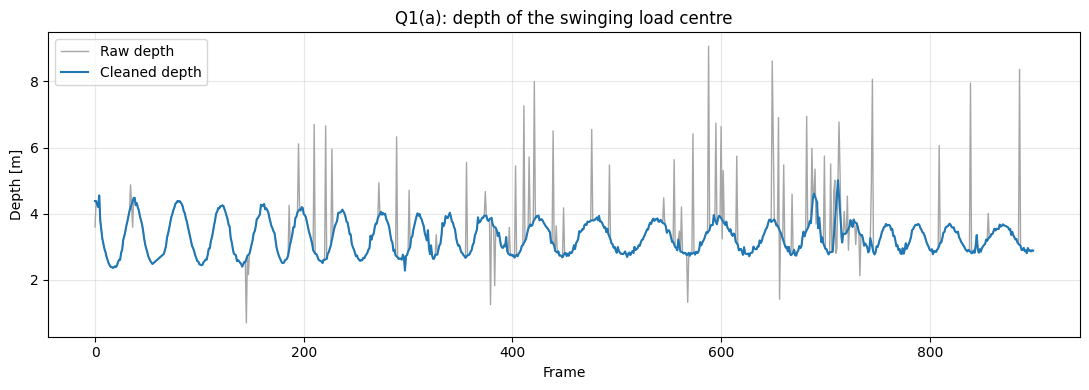

In [9]:
# Step 4: Remove large depth outliers using a local median, then interpolate
WINDOW = 7
THRESHOLD_M = 0.5
half_window = WINDOW // 2

depth_clean = depth_array.copy()
for i in range(len(depth_array)):
    start, end = max(0, i - half_window), min(len(depth_array), i + half_window + 1)
    local_median = np.nanmedian(depth_array[start:end])
    if np.isnan(depth_array[i]) or abs(depth_array[i] - local_median) > THRESHOLD_M:
        depth_clean[i] = np.nan

valid = ~np.isnan(depth_clean)
depth_clean = np.interp(np.arange(len(depth_clean)), np.flatnonzero(valid), depth_clean[valid])

print("Number of corrected depth values:", int(np.sum(~valid)))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(frame_ids, depth_array, color="0.65", linewidth=1, label="Raw depth")
ax.plot(frame_ids, depth_clean, color="tab:blue", linewidth=1.5, label="Cleaned depth")
ax.set_xlabel("Frame")
ax.set_ylabel("Depth [m]")
ax.set_title("Q1(a): depth of the swinging load centre")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [10]:
# Step 5: Back-project (u, v, depth) to 3D camera coordinates using M_int
def back_project(centers, depths, K):
    # Pinhole model: X = (u - cx) Z / fx,  Y = (v - cy) Z / fy
    fx, fy, cx, cy = K[0, 0], K[1, 1], K[0, 2], K[1, 2]
    uv = np.asarray(centers, dtype=float)
    Z = np.asarray(depths, dtype=float)
    X = (uv[:, 0] - cx) * Z / fx
    Y = (uv[:, 1] - cy) * Z / fy
    return np.column_stack([X, Y, Z])


o1 = back_project(centers, depth_clean, M_int)

print("Number of 3D coordinates:", len(o1))
print("First 3D coordinate o1 [X, Y, Z] (m):", np.round(o1[0], 4))

Number of 3D coordinates: 889
First 3D coordinate o1 [X, Y, Z] (m): [    -1.8052     -1.0079      4.3838]


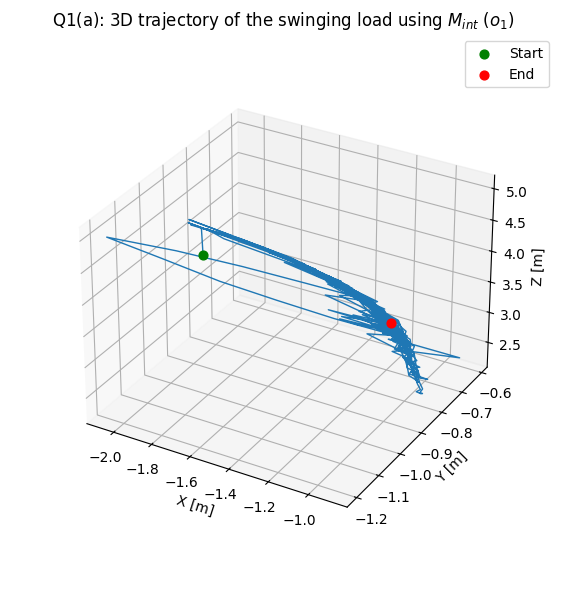

In [11]:
# Step 6: Plot the 3D trajectory o1
def plot_trajectory(points, title, color):
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")
    ax.plot(points[:, 0], points[:, 1], points[:, 2], color=color, linewidth=1)
    ax.scatter(*points[0], color="green", s=40, label="Start")
    ax.scatter(*points[-1], color="red", s=40, label="End")
    ax.set_xlabel("X [m]")
    ax.set_ylabel("Y [m]")
    ax.set_zlabel("Z [m]")
    ax.set_title(title)
    ax.set_box_aspect(None, zoom=0.85)  # keep the Z label inside the figure
    ax.legend()
    plt.tight_layout()
    plt.show()


plot_trajectory(o1, "Q1(a): 3D trajectory of the swinging load using $M_{int}$ ($o_1$)", "tab:blue")

## (b)

### Task:
Say, the default intrinsic matrix of L515 is

$$
M_d =
\begin{bmatrix}
1342 & 0 & 325 \\
0 & 1342 & 235 \\
0 & 0 & 1
\end{bmatrix}
$$

Use this matrix to find the 3D coordinates of the centre of the swinging load for all frames ($o_2$) and plot them.

### Approach:
1. Define the default intrinsic matrix $M_d$.
2. Use the same centre pixels $(u, v)$ and cleaned depth values as in part (a).
3. Use $M_d$ to convert $(u, v, depth)$ into 3D camera coordinates $o_2$ and plot the trajectory.

In [12]:
# Step 1-2: Default L515 intrinsic matrix and 3D coordinates o2
Md = np.array([
    [1342.0, 0.0, 325.0],
    [0.0, 1342.0, 235.0],
    [0.0, 0.0, 1.0],
])
print("Md =")
print(Md)

o2 = back_project(centers, depth_clean, Md)

print("\nNumber of 3D coordinates:", len(o2))
print("First point o1 [X, Y, Z] (m):", np.round(o1[0], 4))
print("First point o2 [X, Y, Z] (m):", np.round(o2[0], 4))

Md =
[[       1342           0         325]
 [          0        1342         235]
 [          0           0           1]]

Number of 3D coordinates: 889
First point o1 [X, Y, Z] (m): [    -1.8052     -1.0079      4.3838]
First point o2 [X, Y, Z] (m): [     0.2646     -0.0457      4.3838]


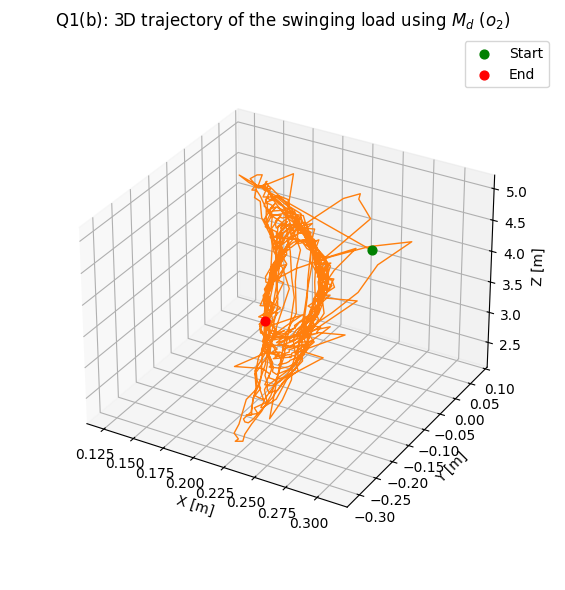

In [13]:
# Step 3: Plot the 3D trajectory o2
plot_trajectory(o2, "Q1(b): 3D trajectory of the swinging load using $M_d$ ($o_2$)", "tab:orange")

The same detected centre pixels and cleaned depth values from part (a) were used, so $o_1$ and $o_2$ have identical $Z$ values. Only $X$ and $Y$ change, because they depend on the focal lengths and principal point of the intrinsic matrix.

## (c)

### Task:
Which intrinsic matrix, $M_{int}$ or $M_d$, is more accurate? Give reasons for the answer.

### Approach:
1. Compare the intrinsic parameters in $M_{int}$ and $M_d$.
2. Compare the principal point values with the image resolution.
3. Compare the focal length values with the camera specification.

In [14]:
# Compare the intrinsic parameters with the image centre
image_height, image_width = plt.imread(rgb_files[0]).shape[:2]
print(f"Image resolution: {image_width} x {image_height} -> image centre ({image_width / 2:.0f}, {image_height / 2:.0f})\n")

print(f"{'Parameter':<10}{'M_int':>12}{'M_d':>12}")
for name, (row, col) in {"fx": (0, 0), "fy": (1, 1), "cx": (0, 2), "cy": (1, 2)}.items():
    print(f"{name:<10}{M_int[row, col]:>12.2f}{Md[row, col]:>12.2f}")

Image resolution: 640 x 480 -> image centre (320, 240)

Parameter        M_int         M_d
fx             1391.72     1342.00
fy             1388.53     1342.00
cx              979.10      325.00
cy              540.25      235.00


### Answer:

The default intrinsic matrix $M_d$ appears to be more accurate for the images used in this assignment.

- **Principal point:** The images have a resolution of 640 × 480 pixels, so the image centre is approximately (320, 240). The principal point in $M_d$ is (325, 235), which is very close to the image centre. The principal point in $M_{int}$ is approximately (979, 540), which is the centre of a 1920 × 1080 image. $M_{int}$ was therefore calibrated at a different resolution and cannot be used directly on 640 × 480 frames without rescaling.
- **Focal length:** The lecture notes show that the focal length of the L515/OV2740 camera is approximately 1285 pixels. The focal length in $M_d$ is 1342 pixels, while $M_{int}$ gives approximately 1390 pixels, so $M_d$ is also closer to the expected focal length.

Based on both the principal point and the focal length, $M_d$ is more suitable for the 640 × 480 images used in this assignment. With $M_{int}$, the trajectory in (a) is shifted by roughly $(979-320)\,Z/f_x \approx 2$ m in $X$ at 4 m depth, which does not match the load hanging close to the centre of the image.

## (d)

### Task:
From the data obtained in parts (a) and (b), $o_1$ and $o_2$, implement a machine learning model that learns the function

$$
f_\theta(o_1) = o_2^*
$$

and explain the results using relevant KPIs.

### Approach:
1. Use $o_1$ as input and $o_2$ as target, and split the data into training and test sets (80/20).
2. Train a linear regression model.
3. Predict $o_2^*$ for the test set and evaluate RMSE, MAE and $R^2$.

In [15]:
# Step 1-2: Split the data and train a linear regression model
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(o1, o2, test_size=0.2, random_state=42)

model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

print("Training samples:", len(X_train))
print("Test samples:    ", len(X_test))
print("\nLearned weight matrix (rows: X*, Y*, Z*; columns: X1, Y1, Z1):")
print(np.round(model_lr.coef_, 4))
print("Learned intercept:", np.round(model_lr.intercept_, 6))

Training samples: 711
Test samples:     178

Learned weight matrix (rows: X*, Y*, Z*; columns: X1, Y1, Z1):
[[      1.037           0      0.4874]
 [          0      1.0347      0.2275]
 [         -0           0           1]]
Learned intercept: [          0           0          -0]


KPI                  X           Y           Z     Overall
RMSE [m]      1.03e-15    2.95e-16    6.30e-16    7.20e-16
MAE [m]       1.03e-15    2.65e-16    4.89e-16    5.94e-16
R²            1.000000    1.000000    1.000000    1.000000


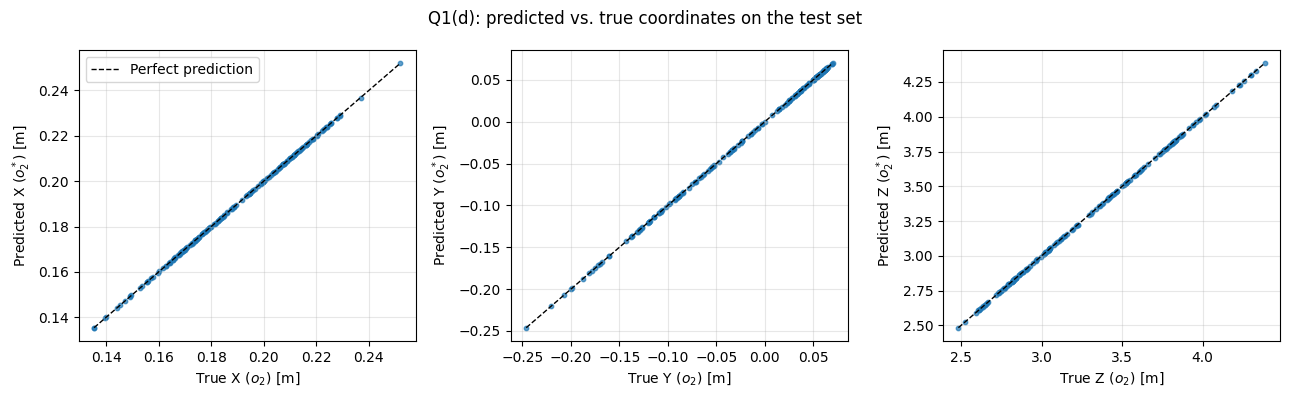

In [16]:
# Step 3: Predict o2* for the test set and evaluate the KPIs
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

o2_star = model_lr.predict(X_test)

print(f"{'KPI':<10}{'X':>12}{'Y':>12}{'Z':>12}{'Overall':>12}")
rmse_axis = np.sqrt(mean_squared_error(y_test, o2_star, multioutput="raw_values"))
mae_axis = mean_absolute_error(y_test, o2_star, multioutput="raw_values")
r2_axis = r2_score(y_test, o2_star, multioutput="raw_values")
print(f"{'RMSE [m]':<10}" + "".join(f"{value:>12.2e}" for value in rmse_axis)
      + f"{np.sqrt(mean_squared_error(y_test, o2_star)):>12.2e}")
print(f"{'MAE [m]':<10}" + "".join(f"{value:>12.2e}" for value in mae_axis)
      + f"{mean_absolute_error(y_test, o2_star):>12.2e}")
print(f"{'R²':<10}" + "".join(f"{value:>12.6f}" for value in r2_axis)
      + f"{r2_score(y_test, o2_star):>12.6f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, i, label in zip(axes, range(3), "XYZ"):
    ax.scatter(y_test[:, i], o2_star[:, i], s=10, alpha=0.7)
    limits = [y_test[:, i].min(), y_test[:, i].max()]
    ax.plot(limits, limits, "k--", linewidth=1, label="Perfect prediction")
    ax.set_xlabel(f"True {label} ($o_2$) [m]")
    ax.set_ylabel(f"Predicted {label} ($o_2^*$) [m]")
    ax.grid(True, alpha=0.3)
axes[0].legend()
fig.suptitle("Q1(d): predicted vs. true coordinates on the test set")
plt.tight_layout()
plt.show()

### Results

The linear regression model predicts $o_2$ from $o_1$ almost perfectly: RMSE and MAE are at the level of floating-point round-off (about $10^{-16}$ m) and $R^2 = 1.0$ for all three axes. All test points lie on the line of perfect prediction.

This is expected, because both coordinate sets are computed from the same pixels and depths. Eliminating $u$ and $v$ from the pinhole equations gives

$$
X_2 = \frac{f_x}{f_{x,d}} X_1 + \frac{c_x - c_{x,d}}{f_{x,d}} Z_1, \qquad
Y_2 = \frac{f_y}{f_{y,d}} Y_1 + \frac{c_y - c_{y,d}}{f_{y,d}} Z_1, \qquad
Z_2 = Z_1,
$$

which is an exact linear function of $o_1$. The learned weight matrix matches these coefficients (for example $f_x / f_{x,d} = 1391.7/1342 \approx 1.037$ and $(c_x - c_{x,d})/f_{x,d} = (979.1-325)/1342 \approx 0.487$). The model therefore learns the change of intrinsic matrix, not a physical correction of the measurement.

## (e)

### Task:
Find the Euclidean error between (i) $o_1$ and $o_2$ and (ii) $o_1$ and $o_2^*$, and interpret the results.

### Approach:
1. Calculate the Euclidean distance between corresponding points of $o_1$ and $o_2$ (all frames and test frames).
2. Calculate the Euclidean distance between the test points of $o_1$ and the predictions $o_2^*$.
3. Compare the errors on the same test frames.

Comparison                    Frames   Mean [m]    Min [m]    Max [m]
(i)  o1 vs o2, all frames        889     1.7181     1.1894     2.6103
(i)  o1 vs o2, test frames       178     1.7133     1.2927     2.2809
(ii) o1 vs o2*, test frames      178     1.7133     1.2927     2.2809


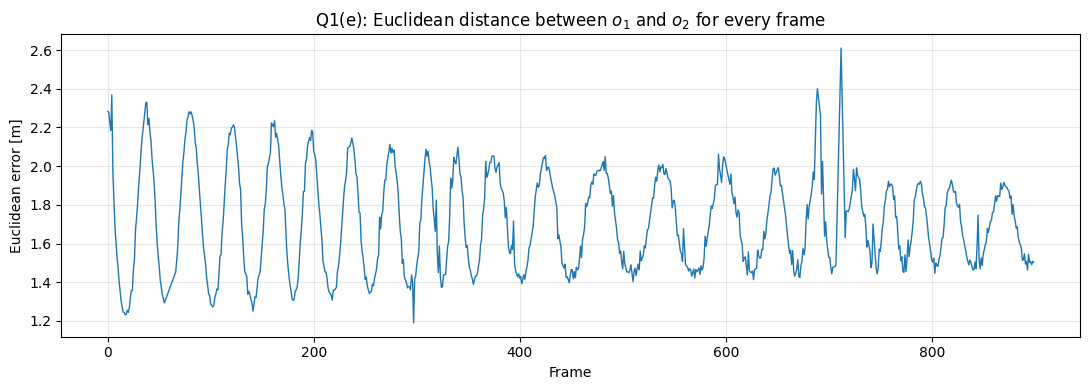

In [17]:
# Euclidean errors per frame
error_o1_o2_all = np.linalg.norm(o1 - o2, axis=1)
error_o1_o2_test = np.linalg.norm(X_test - y_test, axis=1)
error_o1_o2star = np.linalg.norm(X_test - o2_star, axis=1)

print(f"{'Comparison':<28}{'Frames':>8}{'Mean [m]':>11}{'Min [m]':>11}{'Max [m]':>11}")
for name, error in [("(i)  o1 vs o2, all frames", error_o1_o2_all),
                    ("(i)  o1 vs o2, test frames", error_o1_o2_test),
                    ("(ii) o1 vs o2*, test frames", error_o1_o2star)]:
    print(f"{name:<28}{len(error):>8}{error.mean():>11.4f}{error.min():>11.4f}{error.max():>11.4f}")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(frame_ids, error_o1_o2_all, color="tab:blue", linewidth=1)
ax.set_xlabel("Frame")
ax.set_ylabel("Euclidean error [m]")
ax.set_title("Q1(e): Euclidean distance between $o_1$ and $o_2$ for every frame")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Results

(i) The mean Euclidean error between $o_1$ and $o_2$ is about 1.72 m over all frames, ranging from about 1.2 m to 2.6 m.

(ii) On the test frames, the error between $o_1$ and $o_2^*$ is the same as the error between $o_1$ and $o_2$ (to within round-off), because the regression model reproduces $o_2$ exactly.

The large difference comes only from the choice of intrinsic matrix. Since the $X$ and $Y$ offsets grow with depth ($\Delta X \approx 0.49\,Z$ and $\Delta Y \approx 0.23\,Z$), the error grows when the load swings further from the camera, which explains the variation along the frames. Choosing the correct intrinsic matrix is therefore critical: a wrong principal point gives errors of metres, even with a perfect depth measurement.

# Q2. Lidar

## (a)

### Task:
Use Ouster lidar data to find the center of the swinging load for all frames and plot the trajectory.

### Approach:
1. Load the lidar point cloud data for each frame.
2. Use clustering to separate the swinging load from the other points in the scene.
3. Find the centroid of the cluster representing the swinging load.
4. Save the centroid for each frame and plot the complete 3D trajectory.

### Data and method

The supplied Ouster OS-1 recording is read with its matching sensor metadata. Each complete scan is converted to XYZ points in metres. For part (a), DBSCAN isolates the compact moving load cluster in a checked region of the sensor frame, and the mean XYZ of that cluster is tracked across scans. Part (b) applies KISS-ICP to consecutive complete scans to estimate sensor motion. Sensor pose and load-centroid position are different quantities.

In [18]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from kiss_icp.config import KISSConfig
from kiss_icp.config.config import DataConfig, MappingConfig
from kiss_icp.kiss_icp import KissICP
from ouster.sdk import open_source
from ouster.sdk.client import ChanField, XYZLut
from sklearn.cluster import DBSCAN

DATA_DIR = Path.cwd() / "lidar-pcd processing-2026 class-2" / "lidar-pcd processing-2026 class"
PCAP_PATH = DATA_DIR / "swinging_load.pcap"
METADATA_PATH = DATA_DIR / "swinging_load.json"
if not PCAP_PATH.is_file() or not METADATA_PATH.is_file():
    raise FileNotFoundError(
        f"Expected the Ouster recording and metadata in {DATA_DIR}. "
        "Update DATA_DIR if the class folder is stored elsewhere."
    )

# This crop contains the compact moving cluster; tune it if the recording changes.
LOAD_XYZ_BOUNDS = np.array([[-0.5, 1.8], [0.7, 2.8], [-0.4, 1.0]])
LOAD_RANGE_BOUNDS_M = (0.5, 8.0)
DBSCAN_EPS_M = 0.18
DBSCAN_MIN_SAMPLES = 5
MIN_LOAD_CLUSTER_POINTS = 250
MAX_TRACK_STEP_M = 0.5

# KISS-ICP estimates sensor motion against the static scene, not load motion.
kiss_config = KISSConfig(
    data=DataConfig(min_range=1.0, max_range=30.0, deskew=False),
    mapping=MappingConfig(voxel_size=0.5),
)
kiss = KissICP(kiss_config)

source = open_source(str(PCAP_PATH), meta=[str(METADATA_PATH)])
xyz_lut = XYZLut(source.metadata)
frame_ids = []
frame_times_s = []
load_centers = []
load_cluster_sizes = []
sensor_poses = []
previous_center = None
first_timestamp_s = None

for scan in source:
    if not scan.complete():
        continue

    xyz_image = xyz_lut(scan)
    range_image_m = scan.field(ChanField.RANGE).astype(np.float64) * 1e-3
    finite = np.isfinite(xyz_image).all(axis=2)

    load_mask = (
        finite
        & (range_image_m > LOAD_RANGE_BOUNDS_M[0])
        & (range_image_m < LOAD_RANGE_BOUNDS_M[1])
    )
    for axis in range(3):
        load_mask &= xyz_image[:, :, axis] >= LOAD_XYZ_BOUNDS[axis, 0]
        load_mask &= xyz_image[:, :, axis] <= LOAD_XYZ_BOUNDS[axis, 1]
    load_points = xyz_image[load_mask]

    candidates = []
    if len(load_points) >= MIN_LOAD_CLUSTER_POINTS:
        labels = DBSCAN(
            eps=DBSCAN_EPS_M,
            min_samples=DBSCAN_MIN_SAMPLES,
            n_jobs=-1,
        ).fit_predict(load_points)
        for label in np.unique(labels):
            if label < 0:
                continue
            cluster = load_points[labels == label]
            if len(cluster) < MIN_LOAD_CLUSTER_POINTS:
                continue
            center = cluster.mean(axis=0)
            distance = (
                0.0 if previous_center is None
                else float(np.linalg.norm(center - previous_center))
            )
            candidates.append((distance, -len(cluster), center, len(cluster)))

    selected = min(candidates, key=lambda item: (item[0], item[1])) if candidates else None
    if selected is not None and (previous_center is None or selected[0] <= MAX_TRACK_STEP_M):
        center, cluster_size = selected[2], selected[3]
        load_centers.append(center)
        load_cluster_sizes.append(cluster_size)
        previous_center = center
    else:
        load_centers.append([np.nan, np.nan, np.nan])
        load_cluster_sizes.append(0)

    nonzero_timestamps = scan.timestamp[scan.timestamp > 0]
    if not len(nonzero_timestamps):
        raise ValueError(f"Complete scan {scan.frame_id} has no valid timestamps")
    timestamp_s = float(np.median(nonzero_timestamps)) * 1e-9
    if first_timestamp_s is None:
        first_timestamp_s = timestamp_s
    frame_times_s.append(timestamp_s - first_timestamp_s)
    frame_ids.append(int(scan.frame_id))

    # KISS-ICP expects XYZ and one time per point; deskew is disabled here.
    kiss_mask = (
        finite
        & (range_image_m >= kiss_config.data.min_range)
        & (range_image_m <= kiss_config.data.max_range)
        & (range_image_m > 0)
    )
    kiss_points = xyz_image[kiss_mask]
    column_times_s = np.tile(scan.timestamp, (scan.h, 1)).astype(np.float64) * 1e-9
    column_times_s -= column_times_s.min()
    kiss.register_frame(kiss_points, column_times_s[kiss_mask])
    sensor_poses.append(kiss.last_pose.copy())

source.close()
frame_ids = np.asarray(frame_ids, dtype=int)
frame_times_s = np.asarray(frame_times_s, dtype=float)
load_centers = np.asarray(load_centers, dtype=float)
load_cluster_sizes = np.asarray(load_cluster_sizes, dtype=int)
sensor_poses = np.asarray(sensor_poses, dtype=float)
load_valid = np.isfinite(load_centers).all(axis=1)
if not len(frame_ids):
    raise RuntimeError("No complete Ouster scans were decoded from the recording")
if not load_valid.any():
    raise RuntimeError("The load cluster was not detected in any complete scan")

print(f"Complete scans decoded: {len(frame_ids)}")
print(f"Load centroids detected: {int(load_valid.sum())}/{len(frame_ids)}")
print("Detected load-centroid bounds [m]:")
print(np.round(np.nanmin(load_centers, axis=0), 3))
print(np.round(np.nanmax(load_centers, axis=0), 3))
if not load_valid.all():
    print("Scans without a load detection:", frame_ids[~load_valid].tolist())

loading metadata from ['c:\\Users\\resjw\\Downloads\\lidar-pcd processing-2026 class-2\\lidar-pcd processing-2026 class\\swinging_load.json']
Complete scans decoded: 99
Load centroids detected: 99/99
Detected load-centroid bounds [m]:
[      0.643       1.354       0.157]
[      0.783       2.139       0.231]


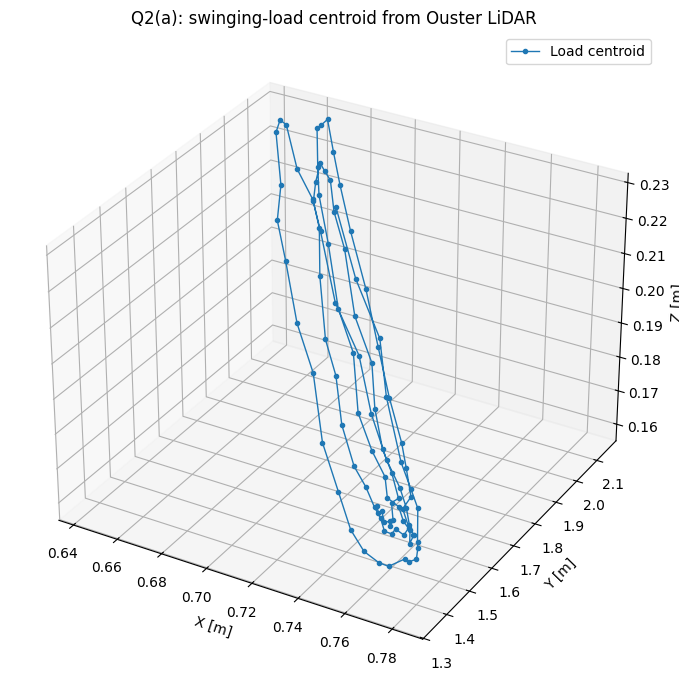

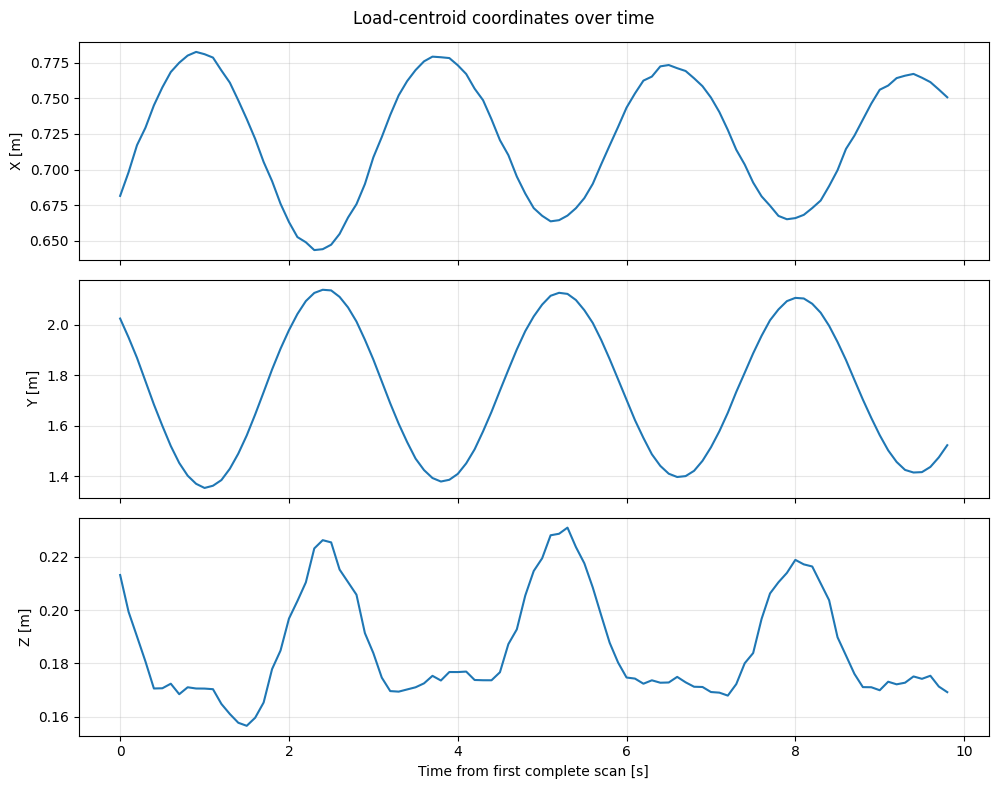

In [19]:
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
ax.plot(
    load_centers[load_valid, 0],
    load_centers[load_valid, 1],
    load_centers[load_valid, 2],
    "o-",
    markersize=3,
    linewidth=1,
    label="Load centroid",
)
ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z [m]")
ax.set_title("Q2(a): swinging-load centroid from Ouster LiDAR")
ax.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for axis, coordinate, label in zip(axes, range(3), ("X", "Y", "Z")):
    axis.plot(frame_times_s[load_valid], load_centers[load_valid, coordinate])
    axis.set_ylabel(f"{label} [m]")
    axis.grid(True, alpha=0.3)
axes[-1].set_xlabel("Time from first complete scan [s]")
fig.suptitle("Load-centroid coordinates over time")
fig.tight_layout()
plt.show()

### Q2(b): KISS-ICP method and interpretation

KISS-ICP (Keep It Small and Simple ICP) estimates LiDAR odometry by aligning each scan to a local voxel map. It filters and voxel-downsamples points, predicts the next pose from recent motion, performs robust point-to-map ICP, then updates the pose, local map, and adaptive correspondence threshold. It is useful when a LiDAR-equipped platform needs local motion estimates without camera imagery or a learned model.

Its limitations matter here: pose estimates can drift over time, become unreliable in geometrically repetitive or sparse scenes, and be biased by moving objects. This recording uses a stationary sensor, so near-zero KISS-ICP motion is expected; it does not mean the load is stationary. KISS-ICP estimates the sensor pose, not the object's pose. The next cell transforms each detected load centroid into the first-scan reference frame using the corresponding estimated sensor pose. The transformed centroid provides position only; it is not a full rigid-body orientation estimate for the load.

KISS-ICP poses estimated: 99
Maximum estimated sensor translation from first scan [m]: 0.0046
Maximum estimated sensor rotation from first scan [deg]: 0.0191
First sensor pose [4x4]:
[[          1           0           0           0]
 [          0           1           0           0]
 [          0           0           1           0]
 [          0           0           0           1]]


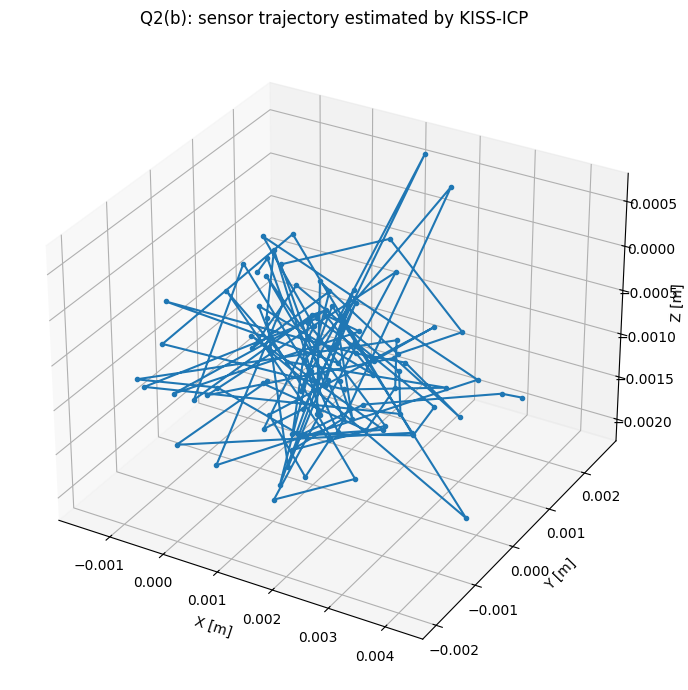

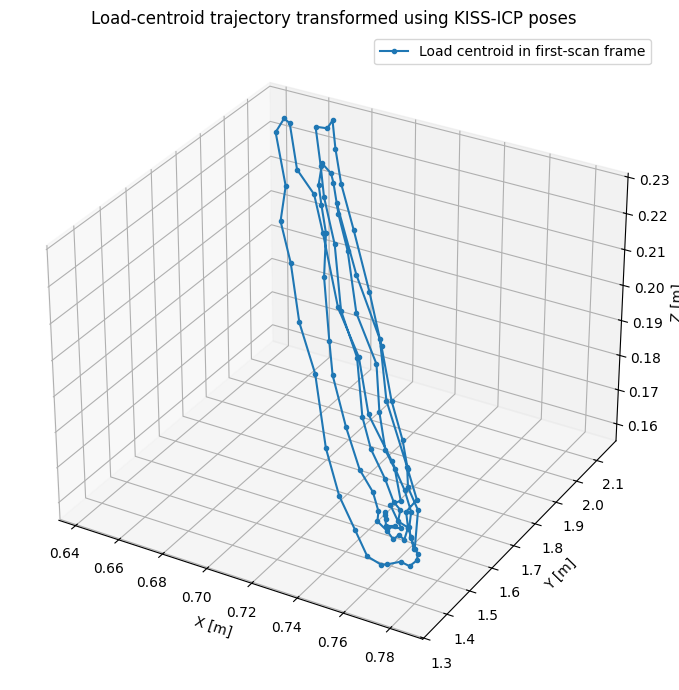

In [20]:
# KISS-ICP poses map each sensor scan into the first-scan reference frame.
load_centers_reference = np.full_like(load_centers, np.nan)
for index in np.flatnonzero(load_valid):
    load_centers_reference[index] = (
        sensor_poses[index, :3, :3] @ load_centers[index]
        + sensor_poses[index, :3, 3]
    )

sensor_translation = sensor_poses[:, :3, 3]
rotation_cos = np.clip(
    (np.trace(sensor_poses[:, :3, :3], axis1=1, axis2=2) - 1.0) / 2.0,
    -1.0,
    1.0,
)
sensor_rotation_deg = np.degrees(np.arccos(rotation_cos))
print(f"KISS-ICP poses estimated: {len(sensor_poses)}")
print(
    "Maximum estimated sensor translation from first scan [m]:",
    round(float(np.linalg.norm(sensor_translation, axis=1).max()), 4),
)
print(
    "Maximum estimated sensor rotation from first scan [deg]:",
    round(float(sensor_rotation_deg.max()), 4),
)
print("First sensor pose [4x4]:")
print(np.round(sensor_poses[0], 4))

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
ax.plot(sensor_translation[:, 0], sensor_translation[:, 1], sensor_translation[:, 2], "o-", markersize=3)
ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z [m]")
ax.set_title("Q2(b): sensor trajectory estimated by KISS-ICP")
plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
ax.plot(
    load_centers_reference[load_valid, 0],
    load_centers_reference[load_valid, 1],
    load_centers_reference[load_valid, 2],
    "o-",
    markersize=3,
    label="Load centroid in first-scan frame",
)
ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z [m]")
ax.set_title("Load-centroid trajectory transformed using KISS-ICP poses")
ax.legend()
plt.tight_layout()
plt.show()

### Results from the supplied recording

The decoder produced 99 complete scans, and the load cluster was detected in all 99. The tracked centroid was within X = 0.643-0.783 m, Y = 1.354-2.139 m, and Z = 0.157-0.231 m. The 0.785 m span in Y shows the swinging motion in this recording.

KISS-ICP returned a pose for each scan. The maximum estimated sensor displacement from the first scan was 0.0046 m and the maximum rotation was 0.0191 degrees, consistent with a stationary sensor. These near-zero sensor-motion estimates are not the swinging-load trajectory; use the centroid plot for that. The transformed centroid coordinates are in the first-scan reference frame.

# Q3. Camera-Lidar fusion

## (a)

### Task:
Get familiar with the KITTI data set. There are multiple cameras and Lidar used. It contains information about images taken from cameras, point cloud taken from lidar, and camera matrices. Illustrate your understanding in presentation.

### Approach:
1. Inspect the KITTI training data structure.
2. Understand what the camera images, LiDAR point clouds, calibration files, and labels contain.
3. Explain how the camera and LiDAR data are related through the calibration matrices.
4. Use examples from the training data to illustrate the dataset structure.

### KITTI sensors, files, and coordinate frames

KITTI's 3D-detection recordings associate camera images with Velodyne LiDAR scans, calibration, and object labels. Matching frame IDs link files such as:

- `image_2/000004.png`: rectified colour image from camera 2.
- `velodyne/000004.bin`: float32 `(x, y, z, reflectance)` samples in the LiDAR frame.
- `calib/000004.txt`: camera projections (`P0`-`P3`), rectification (`R0_rect`), and LiDAR-to-camera transform (`Tr_velo_to_cam`).
- `label_2/000004.txt`: object class, 2D box, 3D dimensions, location, and yaw.

For a LiDAR point in homogeneous coordinates, transform to the rectified camera frame with `R0_rect @ Tr_velo_to_cam`, then project using `P2`. Divide projected x and y by the third homogeneous component to obtain pixel `(u, v)`. Only points in front of the camera and inside the image are retained. Calibration maps between different sensor origins and coordinate axes; it is essential for alignment.

The local `Dataset_KITTI` YOLO subset contains JPG images and normalized 2D labels, but no matching raw LiDAR or calibration. For the actual fusion demonstration below, five frames are randomly sampled (seed 512) from a compact KITTI 3D training subset; only those frames' images, point clouds, calibration, and labels are used. This avoids downloading the full 46.08 GB release.

### Presentation-ready outline

1. **Sensors and files:** synchronized camera images, Velodyne point clouds, calibration matrices, and KITTI object labels share frame IDs.
2. **Coordinate transforms:** apply `Tr_velo_to_cam`, `R0_rect`, and `P2` to map each LiDAR point into camera pixels; reject points behind/outside the image.
3. **Fusion and distance:** overlay projected LiDAR colored by sensor range on each camera image, show YOLO vehicle boxes and the range estimate beside the selected box.
4. **Validation:** compare the LiDAR range with the matched KITTI 3D ground-truth location; report box IoU, per-frame absolute range error, and mean absolute error. A detection without a valid ground-truth box match is reported as unmatched, not included in the distance-error average.
5. **Data scope:** the local 190-image YOLO subset has no paired LiDAR. The fusion example therefore uses five randomly selected synchronized frames from a compact KITTI training subset (about 13.6 MB), rather than claiming that the local 2D subset supports fusion.

The annotated JPG below illustrates the local 2D subset. The five-frame figure further down is the actual camera–LiDAR fusion and range-validation example.

Dataset subset: c:\Users\resjw\Downloads\Dataset_KITTI\kitti_car_subset-54816d98
Configured classes: {0: 'car', 1: 'van', 2: 'truck', 3: 'pedestrian', 4: 'person_sitting', 5: 'cyclist', 6: 'tram', 7: 'misc'}
Split summary: {'train': {'images': 150, 'label_files': 150, 'missing_labels': 0}, 'val': {'images': 40, 'label_files': 40, 'missing_labels': 0}}
Annotated boxes by class: {'car': 833, 'van': 87, 'truck': 34, 'pedestrian': 99, 'cyclist': 21, 'tram': 19, 'misc': 23}
Full KITTI image_2/ present: False
Full KITTI velodyne/ present: False
Full KITTI calib/ present: False
Full KITTI label_2/ present: False


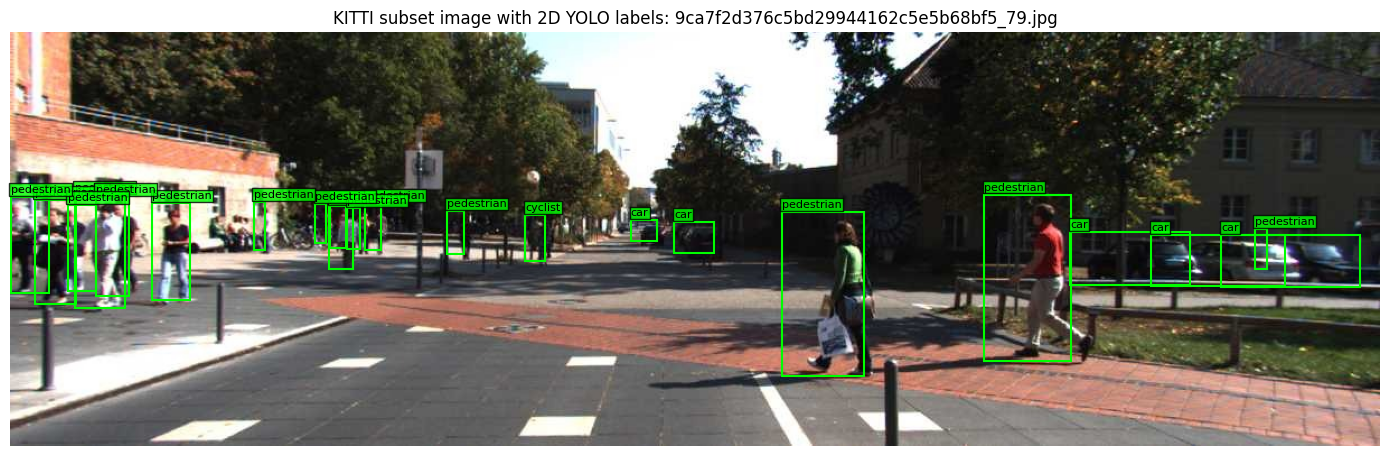

In [21]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
import yaml

KITTI_SEARCH_ROOTS = [
    Path.cwd() / "Dataset_KITTI",
    Path.cwd() / "MAS512_Group9_data" / "Dataset_KITTI",
]
kitti_root = next((root for root in KITTI_SEARCH_ROOTS if root.is_dir()), None)
if kitti_root is None:
    raise FileNotFoundError(
        "Could not find Dataset_KITTI. Set kitti_root to the folder containing "
        "the downloaded KITTI subset."
    )
subsets = sorted(kitti_root.glob("kitti_car_subset-*"))
if not subsets:
    raise FileNotFoundError(f"No kitti_car_subset-* directory found under {kitti_root}")
kitti_subset = subsets[0]
data_yaml = kitti_subset / "data.yaml"
if not data_yaml.is_file():
    raise FileNotFoundError(f"Missing dataset metadata: {data_yaml}")
with data_yaml.open(encoding="utf-8") as file:
    kitti_config = yaml.safe_load(file)
class_names = {int(key): value for key, value in kitti_config["names"].items()}

split_counts = {}
class_counts = Counter()
for split in ("train", "val"):
    image_dir = kitti_subset / "images" / split
    label_dir = kitti_subset / "labels" / split
    images = sorted(image_dir.glob("*.jpg"))
    labels = sorted(label_dir.glob("*.txt"))
    missing_labels = [image.name for image in images if not (label_dir / f"{image.stem}.txt").is_file()]
    split_counts[split] = {"images": len(images), "label_files": len(labels), "missing_labels": len(missing_labels)}
    for label_file in labels:
        for line_number, line in enumerate(label_file.read_text(encoding="utf-8").splitlines(), start=1):
            if not line.strip():
                continue
            values = line.split()
            if len(values) != 5:
                raise ValueError(f"Unexpected YOLO label at {label_file}:{line_number}: {line}")
            class_id = int(float(values[0]))
            if class_id not in class_names:
                raise ValueError(f"Unknown class id {class_id} in {label_file}")
            class_counts[class_id] += 1

print("Dataset subset:", kitti_subset)
print("Configured classes:", class_names)
print("Split summary:", split_counts)
print("Annotated boxes by class:", {class_names[key]: count for key, count in sorted(class_counts.items())})
for raw_folder in ("image_2", "velodyne", "calib", "label_2"):
    print(f"Full KITTI {raw_folder}/ present:", (kitti_subset / raw_folder).is_dir())

train_images = sorted((kitti_subset / "images" / "train").glob("*.jpg"))
if not train_images:
    raise RuntimeError(f"No training images found under {kitti_subset / 'images' / 'train'}")
sample_image_path = max(
    train_images,
    key=lambda path: len((kitti_subset / "labels" / "train" / f"{path.stem}.txt").read_text(encoding="utf-8").splitlines()),
)
sample_label_path = kitti_subset / "labels" / "train" / f"{sample_image_path.stem}.txt"
image = Image.open(sample_image_path).convert("RGB")
image_width, image_height = image.size
fig, ax = plt.subplots(figsize=(14, 5))
ax.imshow(image)
with sample_label_path.open(encoding="utf-8") as file:
    for line in file:
        if not line.strip():
            continue
        class_id, x_center, y_center, box_width, box_height = map(float, line.split())
        left = (x_center - box_width / 2) * image_width
        top = (y_center - box_height / 2) * image_height
        width = box_width * image_width
        height = box_height * image_height
        ax.add_patch(Rectangle((left, top), width, height, fill=False, edgecolor="lime", linewidth=1.5))
        ax.text(left, max(0, top - 4), class_names[int(class_id)], color="black", fontsize=8,
                bbox={"facecolor": "lime", "alpha": 0.8, "pad": 1})
ax.set_title(f"KITTI subset image with 2D YOLO labels: {sample_image_path.name}")
ax.axis("off")
plt.tight_layout()
plt.show()

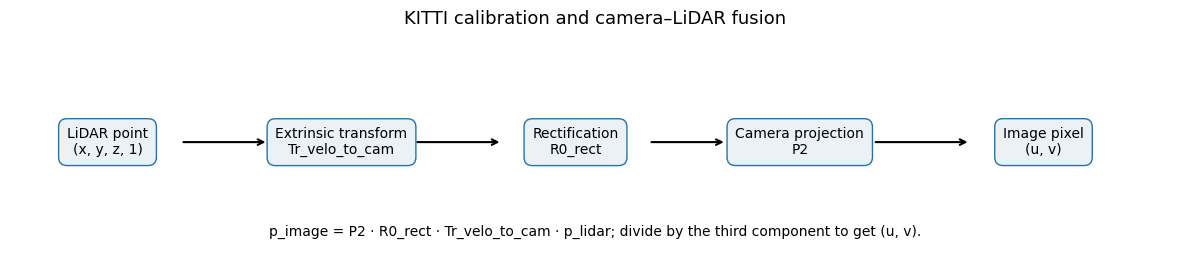

In [22]:
# Coordinate-frame flow for a KITTI LiDAR-to-camera projection.
fig, ax = plt.subplots(figsize=(12, 2.8))
ax.set_xlim(0, 12)
ax.set_ylim(0, 2.8)
ax.axis("off")
steps = [
    (0.2, "LiDAR point\n(x, y, z, 1)"),
    (2.6, "Extrinsic transform\nTr_velo_to_cam"),
    (5.0, "Rectification\nR0_rect"),
    (7.3, "Camera projection\nP2"),
    (9.8, "Image pixel\n(u, v)"),
]
for x, label in steps:
    ax.text(x + 0.8, 1.45, label, ha="center", va="center", fontsize=10,
            bbox={"boxstyle": "round,pad=0.6", "facecolor": "#eaf2f8", "edgecolor": "#2874a6"})
for (x1, _), (x2, _) in zip(steps, steps[1:]):
    ax.annotate("", xy=(x2 + 0.05, 1.45), xytext=(x1 + 1.55, 1.45),
                arrowprops={"arrowstyle": "->", "lw": 1.5})
ax.text(6, 0.35, "p_image = P2 · R0_rect · Tr_velo_to_cam · p_lidar; divide by the third component to get (u, v).",
        ha="center", va="center", fontsize=10)
ax.set_title("KITTI calibration and camera–LiDAR fusion", fontsize=13)
plt.tight_layout()
plt.show()

### Available KITTI data and Q3 fusion samples

The local YOLO subset contains **150 training** and **40 validation** JPGs, each with a YOLO-format 2D label file. Its class counts are: car 833, van 87, pedestrian 99, truck 34, cyclist 21, misc 23, and tram 19. These files alone are not synchronized with raw LiDAR or calibration.

To complete the requested fusion, the next cell uses five reproducibly random frame IDs from a compact KITTI 3D training subset: **000004, 000008, 000019, 000027, and 000029** (NumPy seed 512). Each selected frame includes its corresponding camera image, Velodyne scan, calibration, and 3D labels. The sample files are under `KITTI_Q3_samples/training` in Downloads; the source is [xuehaipiaoxiang/kitti_mini, pinned revision](https://github.com/xuehaipiaoxiang/kitti_mini/tree/af8f29866a7aebbd39234b161e405daa9f9e13e8/kitti_tiny_3D/training).

The fusion visualization projects LiDAR into the camera image, colors points by LiDAR range, puts the estimated distance beside each YOLO box, and compares matched detections to KITTI ground truth. A frame with an unmatched YOLO box is explicitly counted as an association/detection failure rather than assigned an unrelated ground-truth distance.

,Frame,YOLO class,Confidence,KITTI class,2D box IoU,Projected points in box,LiDAR range estimate (m),KITTI GT range (m),Absolute error (m)
0,000004,car,0.53,Car,0.93,116,40.06,41.67,1.61
1,000008,car,0.89,Car,0.86,108,32.57,34.29,1.71
2,000019,car,0.72,Car,0.92,1875,8.91,10.53,1.62
3,000027,car,0.53,Van,0.87,3133,12.90,15.24,2.34
4,000029,car,0.75,Unmatched,0.00,349,22.77,NaN,NaN


Matched detections: 4/5; mean absolute range error on matched detections: 1.82 m


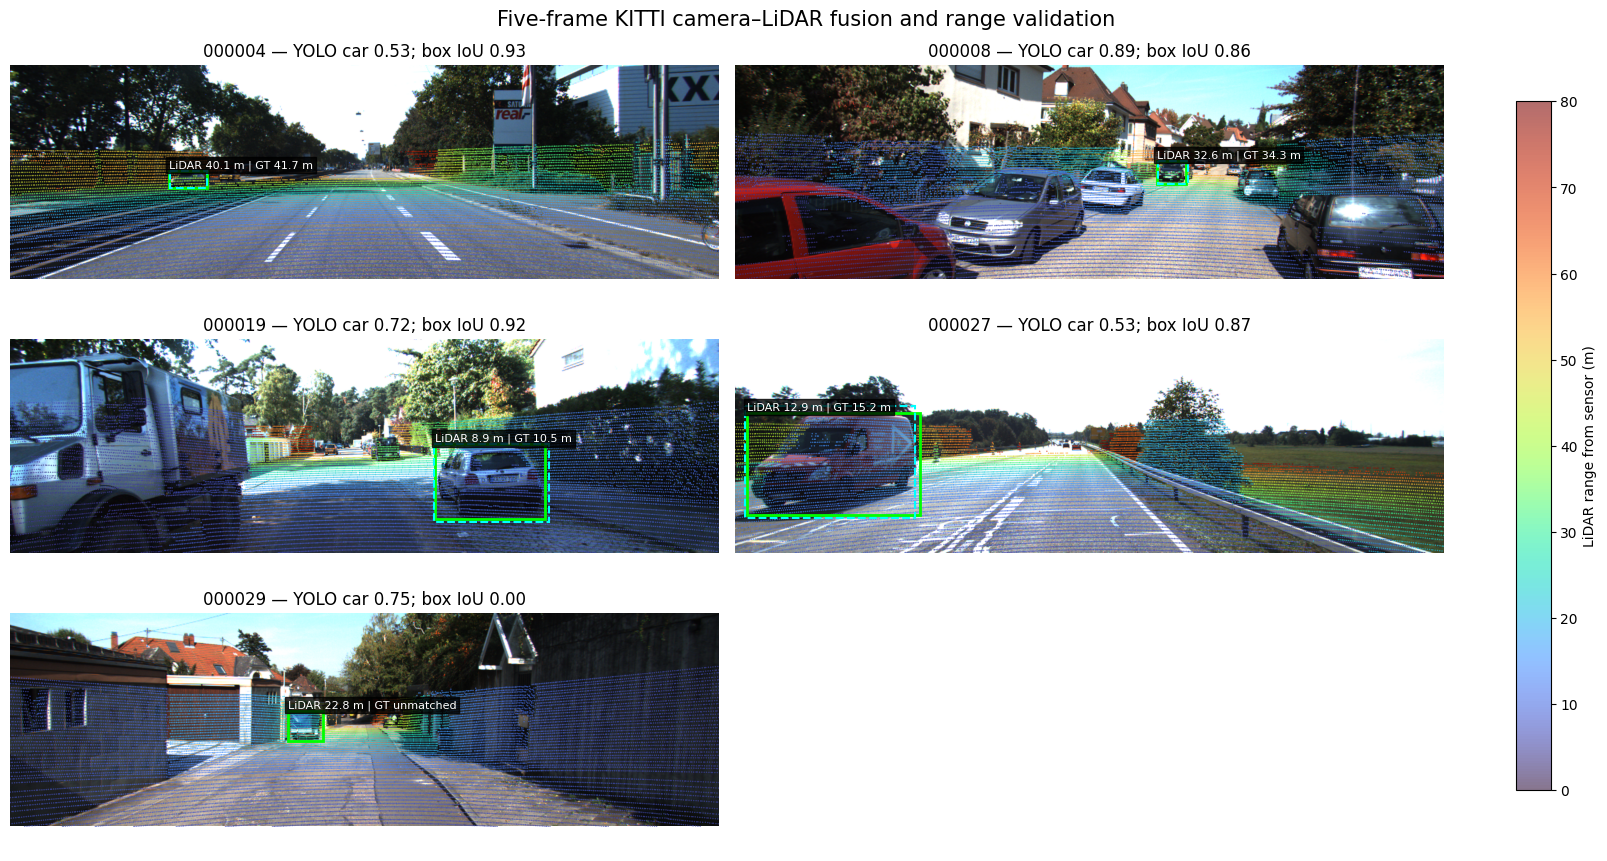

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Rectangle
from PIL import Image
from ultralytics import YOLO

Q3_DATA_ROOT = Path.cwd() / "KITTI_Q3_samples" / "training"
Q3_MODEL_PATH = Path.cwd() / "YOLO_kitti_car.pt"
Q3_SAMPLE_SEED = 512
Q3_TRAINING_FRAME_COUNT = 30
Q3_SAMPLE_COUNT = 5
Q3_VEHICLE_CLASSES = {"car", "van", "truck"}
Q3_MATCH_IOU_THRESHOLD = 0.5

q3_rng = np.random.default_rng(Q3_SAMPLE_SEED)
q3_frame_ids = sorted(
    f"{int(index):06d}"
    for index in q3_rng.choice(Q3_TRAINING_FRAME_COUNT, size=Q3_SAMPLE_COUNT, replace=False)
)
q3_required_paths = [Q3_MODEL_PATH]
for frame_id in q3_frame_ids:
    q3_required_paths.extend(
        [
            Q3_DATA_ROOT / "image_2" / f"{frame_id}.png",
            Q3_DATA_ROOT / "velodyne" / f"{frame_id}.bin",
            Q3_DATA_ROOT / "calib" / f"{frame_id}.txt",
            Q3_DATA_ROOT / "label_2" / f"{frame_id}.txt",
        ]
    )
q3_missing_paths = [file_path for file_path in q3_required_paths if not file_path.is_file()]
if q3_missing_paths:
    raise FileNotFoundError("Missing Q3 input files:\n" + "\n".join(map(str, q3_missing_paths)))


def q3_read_calibration(file_path):
    calibration = {}
    for line in file_path.read_text(encoding="utf-8").splitlines():
        if ":" in line:
            key, values = line.split(":", 1)
            calibration[key] = np.fromstring(values, sep=" ")
    required_shapes = {"P2": 12, "R0_rect": 9, "Tr_velo_to_cam": 12}
    for key, expected_size in required_shapes.items():
        if key not in calibration or calibration[key].size != expected_size:
            raise ValueError(f"Missing or malformed {key} in {file_path}")
    return calibration


def q3_read_labels(file_path):
    labels = []
    for line_number, line in enumerate(file_path.read_text(encoding="utf-8").splitlines(), start=1):
        fields = line.split()
        if not fields or fields[0] == "DontCare":
            continue
        if len(fields) != 15:
            raise ValueError(f"Expected 15 KITTI label fields at {file_path}:{line_number}")
        labels.append(
            {
                "class": fields[0],
                "bbox": np.array([float(value) for value in fields[4:8]]),
                "location_rect": np.array([float(value) for value in fields[11:14]]),
            }
        )
    return labels


def q3_box_iou(box_a, box_b):
    left = max(box_a[0], box_b[0])
    top = max(box_a[1], box_b[1])
    right = min(box_a[2], box_b[2])
    bottom = min(box_a[3], box_b[3])
    intersection = max(0.0, right - left) * max(0.0, bottom - top)
    area_a = max(0.0, box_a[2] - box_a[0]) * max(0.0, box_a[3] - box_a[1])
    area_b = max(0.0, box_b[2] - box_b[0]) * max(0.0, box_b[3] - box_b[1])
    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0


def q3_project_lidar(frame_id, calibration, image_size):
    point_path = Q3_DATA_ROOT / "velodyne" / f"{frame_id}.bin"
    raw_points = np.fromfile(point_path, dtype=np.float32)
    if raw_points.size == 0 or raw_points.size % 4:
        raise ValueError(f"Invalid float32 XYZI data in {point_path}")
    points_velo = raw_points.reshape(-1, 4)[:, :3].astype(np.float64)
    transform = calibration["Tr_velo_to_cam"].reshape(3, 4)
    rectification = calibration["R0_rect"].reshape(3, 3)
    projection = calibration["P2"].reshape(3, 4)
    points_rect = rectification @ (transform[:, :3] @ points_velo.T + transform[:, 3:4])
    pixels_h = projection[:, :3] @ points_rect + projection[:, 3:4]
    with np.errstate(divide="ignore", invalid="ignore"):
        u = pixels_h[0] / pixels_h[2]
        v = pixels_h[1] / pixels_h[2]
    lidar_range = np.linalg.norm(points_velo, axis=1)
    width, height = image_size
    valid = (
        (points_rect[2] > 0)
        & (pixels_h[2] > 0)
        & np.isfinite(u)
        & np.isfinite(v)
        & (u >= 0)
        & (u < width)
        & (v >= 0)
        & (v < height)
        & np.isfinite(lidar_range)
    )
    return u, v, lidar_range, valid, transform, rectification


def q3_ground_truth_range(label, transform, rectification):
    lidar_to_rect = np.eye(4)
    lidar_to_rect[:3, :3] = rectification @ transform[:, :3]
    lidar_to_rect[:3, 3] = rectification @ transform[:, 3]
    location_velo = np.linalg.solve(lidar_to_rect, np.r_[label["location_rect"], 1.0])[:3]
    return float(np.linalg.norm(location_velo))


q3_detector = YOLO(str(Q3_MODEL_PATH))
q3_records = []
q3_visuals = []
for frame_id in q3_frame_ids:
    image_path = Q3_DATA_ROOT / "image_2" / f"{frame_id}.png"
    image = Image.open(image_path).convert("RGB")
    calibration = q3_read_calibration(Q3_DATA_ROOT / "calib" / f"{frame_id}.txt")
    labels = q3_read_labels(Q3_DATA_ROOT / "label_2" / f"{frame_id}.txt")
    vehicle_labels = [label for label in labels if label["class"].lower() in Q3_VEHICLE_CLASSES]
    u, v, lidar_range, projected, transform, rectification = q3_project_lidar(
        frame_id, calibration, image.size
    )

    prediction = q3_detector.predict(
        source=str(image_path), conf=0.25, iou=0.5, device="cpu", verbose=False
    )[0]
    detections = []
    for box in prediction.boxes:
        class_name = q3_detector.names[int(box.cls.item())].lower()
        if class_name in Q3_VEHICLE_CLASSES:
            detections.append(
                {
                    "class": class_name,
                    "confidence": float(box.conf.item()),
                    "bbox": box.xyxy[0].cpu().numpy().astype(float),
                }
            )
    if not detections:
        raise RuntimeError(f"No vehicle detection was produced for sampled frame {frame_id}")
    detection = max(detections, key=lambda item: item["confidence"])
    gt_match = max(
        vehicle_labels,
        key=lambda label: q3_box_iou(detection["bbox"], label["bbox"]),
        default=None,
    )
    overlap = q3_box_iou(detection["bbox"], gt_match["bbox"]) if gt_match else 0.0
    is_matched = overlap >= Q3_MATCH_IOU_THRESHOLD

    x1, y1, x2, y2 = detection["bbox"]
    points_in_box = projected & (u >= x1) & (u <= x2) & (v >= y1) & (v <= y2)
    point_count = int(points_in_box.sum())
    if point_count < 20:
        raise RuntimeError(
            f"Only {point_count} projected points are inside the sampled detection in frame {frame_id}"
        )
    estimated_range = float(np.percentile(lidar_range[points_in_box], 20))
    gt_range = (
        q3_ground_truth_range(gt_match, transform, rectification) if is_matched else np.nan
    )
    q3_records.append(
        {
            "Frame": frame_id,
            "YOLO class": detection["class"],
            "Confidence": detection["confidence"],
            "KITTI class": gt_match["class"] if is_matched else "Unmatched",
            "2D box IoU": overlap,
            "Projected points in box": point_count,
            "LiDAR range estimate (m)": estimated_range,
            "KITTI GT range (m)": gt_range,
            "Absolute error (m)": abs(estimated_range - gt_range) if is_matched else np.nan,
        }
    )
    q3_visuals.append(
        {
            "frame": frame_id,
            "image": image,
            "u": u,
            "v": v,
            "range": lidar_range,
            "projected": projected,
            "detection": detection,
            "gt_match": gt_match if is_matched else None,
            "overlap": overlap,
            "matched": is_matched,
            "estimated_range": estimated_range,
            "gt_range": gt_range,
        }
    )

q3_fusion_results = pd.DataFrame(q3_records)
display(q3_fusion_results.round(2))
q3_matched_results = q3_fusion_results.dropna(subset=["Absolute error (m)"])
q3_fusion_mae = float(q3_matched_results["Absolute error (m)"].mean())
print(
    f"Matched detections: {len(q3_matched_results)}/{len(q3_fusion_results)}; "
    f"mean absolute range error on matched detections: {q3_fusion_mae:.2f} m"
)

fig, axes = plt.subplots(3, 2, figsize=(16, 8.5), constrained_layout=True)
colorbar_artist = None
for ax, sample in zip(axes.flat, q3_visuals):
    ax.imshow(sample["image"])
    colorbar_artist = ax.scatter(
        sample["u"][sample["projected"]],
        sample["v"][sample["projected"]],
        c=sample["range"][sample["projected"]],
        cmap="turbo",
        vmin=0,
        vmax=80,
        s=1.2,
        alpha=0.58,
        linewidths=0,
    )
    detection = sample["detection"]
    x1, y1, x2, y2 = detection["bbox"]
    ax.add_patch(
        Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="lime", linewidth=2)
    )
    if sample["gt_match"] is not None:
        gt = sample["gt_match"]
        gx1, gy1, gx2, gy2 = gt["bbox"]
        ax.add_patch(
            Rectangle(
                (gx1, gy1), gx2 - gx1, gy2 - gy1,
                fill=False, edgecolor="cyan", linewidth=1.5, linestyle="--"
            )
        )
        range_text = (
            f"LiDAR {sample['estimated_range']:.1f} m | GT {sample['gt_range']:.1f} m"
        )
    else:
        range_text = f"LiDAR {sample['estimated_range']:.1f} m | GT unmatched"
    ax.text(
        max(2, x1), max(14, y1 - 5), range_text,
        color="white", fontsize=8,
        bbox={"facecolor": "black", "alpha": 0.78, "pad": 2},
    )
    ax.set_title(
        f"{sample['frame']} — YOLO {detection['class']} {detection['confidence']:.2f}; "
        f"box IoU {sample['overlap']:.2f}"
    )
    ax.set_xlim(0, sample["image"].width)
    ax.set_ylim(sample["image"].height, 0)
    ax.axis("off")

axes.flat[-1].axis("off")
fig.colorbar(colorbar_artist, ax=list(axes.flat[:-1]), label="LiDAR range from sensor (m)", shrink=0.85)
fig.suptitle("Five-frame KITTI camera–LiDAR fusion and range validation", fontsize=15)
plt.show()

### Q3 fusion results

The reproducible five-frame sample produced **4 valid 2D box associations out of 5** at IoU ≥ 0.50. For those four matches, the mean absolute difference between the LiDAR box-range estimate and the KITTI ground-truth range was **1.82 m**:

| Frame | YOLO / KITTI class | Box IoU | LiDAR estimate (m) | KITTI GT range (m) | Absolute error (m) |
|---|---|---:|---:|---:|---:|
| 000004 | car / Car | 0.93 | 40.06 | 41.67 | 1.61 |
| 000008 | car / Car | 0.86 | 32.57 | 34.29 | 1.71 |
| 000019 | car / Car | 0.92 | 8.91 | 10.53 | 1.62 |
| 000027 | car / Van | 0.87 | 12.90 | 15.24 | 2.34 |
| 000029 | car / no match | 0.00 | 22.77 | — | — |

Frame 000029 is retained as a false-positive/unmatched detection; its estimate is shown, but it is not compared with an unrelated label or included in the MAE. The LiDAR estimate is the 20th percentile of projected point ranges inside the predicted 2D box (favoring the object's visible near surface). KITTI's range is to the labeled 3D object location, so this is a practical range-consistency check, not a comparison of identical physical points. The cyan dashed rectangles are matched KITTI 2D boxes; green rectangles are YOLO predictions.

# Q4. Autonomous navigation and slip estimation

## (a)

### Task:
Instantiate a robot in Webots with camera, lidar, wheel encoders, accelerometer, gyro, GPS and IMU. Navigate towards a predefined object goal with collision avoidance, record the sensors and calculate longitudinal slip.

### Approach:
1. Use a differential-drive robot and a red cylinder as the predefined goal.
2. Follow a waypoint route around a blue box, with a lidar-based obstacle-avoidance rule.
3. Record the sensors and use Webots Supervisor velocity as ground truth.
4. Check the encoder velocity and slip calculation against the recorded measurements.

The simulation runs in **Webots R2025a**, not in Jupyter. These cells analyse saved measurements and can be run independently of Q1-Q3. Keep the supplied `Q4_webots` folder next to the notebook. It contains the worlds, controller and all six completed runs. The controller source is displayed at the end of Q4.

In [ ]:
# Step 1: Locate the project and load each completed trial separately.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle, Circle
from IPython.display import display, Code

Q4_SEARCH_ROOTS = [Path.cwd() / "Q4_webots", Path.cwd() / "webots-prosjekt",
                   Path.home() / "Downloads" / "webots-prosjekt"]
Q4_PROJECT = next((p for p in Q4_SEARCH_ROOTS if (p / "results" / "runs").is_dir()), None)
if Q4_PROJECT is None:
    raise FileNotFoundError("Keep Q4_webots next to this notebook, or update Q4_SEARCH_ROOTS.")
Q4_CASES = ("baseline", "low_slip")
Q4_COLORS = {"baseline": "#cb4b16", "low_slip": "#0072b2"}
q4_runs = {}
for q4_case in Q4_CASES:
    q4_runs[q4_case] = []
    for q4_folder in sorted((Q4_PROJECT / "results" / "runs" / q4_case).glob("run_*")):
        if not (q4_folder / "summary.json").is_file():
            print("Skipping incomplete trial:", q4_folder.name)
            continue
        q4_runs[q4_case].append({
            "id": q4_folder.name, "folder": q4_folder,
            "sensors": pd.read_csv(q4_folder / "sensors.csv"),
            "summary": json.loads((q4_folder / "summary.json").read_text()),
            "metadata": json.loads((q4_folder / "metadata.json").read_text()),
            "lidar": [json.loads(line) for line in (q4_folder / "lidar.jsonl").read_text().splitlines()],
        })
    if not q4_runs[q4_case]:
        raise ValueError(f"No completed trials for {q4_case}.")
    print(f"{q4_case}: {len(q4_runs[q4_case])} completed trials")

baseline: 3 completed trials
low_slip: 3 completed trials


### Simulation setup

The wheel radius is **0.10 m**, track width **0.31 m** and maximum requested forward speed **0.35 m/s**. The robot starts at $(-3,0)$ m. The blue box is centred at $(0,0)$ with footprint $0.70\times0.90$ m. The red cylinder is centred at $(3,0)$ m and has radius 0.22 m.

The waypoints are $(-1.5,0)$, $(-1.5,1.4)$, $(1.5,1.4)$, $(1.5,0)$ and $(2.15,0)$ m. A waypoint is accepted within 0.18 m. **Goal reached** therefore means entering the stopping area in front of the cylinder, not touching it. The measured robot centres finish at approximately $x=1.97$ m.

GPS and Supervisor orientation guide the robot towards the known waypoints. If a front-sector lidar return is below 0.65 m, forward motion stops and a turn is selected. The turn direction is held for 1.2 s to reduce oscillation. The camera is recorded but is not used to detect the target. This is controlled navigation with a known route, not SLAM or camera-based target recognition.

Both worlds use a 16 ms time step and random seed 42. No explicit sensor noise or bias is added.

In [ ]:
# Step 2: Document the recorded sensors and check the time alignment and image files.
q4_sensor_fields = pd.DataFrame([
    ["Encoders", "left_rad, right_rad; omega_left, omega_right", "rad; rad/s", "62.5 Hz"],
    ["GPS", "x_m, y_m, gps_z", "m", "62.5 Hz"],
    ["Accelerometer", "ax, ay, az", "m/s²", "62.5 Hz"],
    ["Gyro", "gx, gy, gz", "rad/s", "62.5 Hz"],
    ["InertialUnit", "roll, pitch, yaw", "rad", "62.5 Hz"],
    ["Lidar", "181 ranges per scan in lidar.jsonl", "m", "62.5 Hz"],
    ["Camera", "160 × 120 PNG images, linked by camera_file", "RGB pixels", "5.21 Hz"],
    ["Slip inputs", "v_enc_m_s, vx_m_s, slip, valid_slip", "m/s; dimensionless", "62.5 Hz"],
], columns=["Sensor / quantity", "Recorded fields", "Units", "Logging rate"])
display(q4_sensor_fields)
q4_checks = []
for q4_case, q4_trials in q4_runs.items():
    for q4_run in q4_trials:
        q4_df, q4_scans = q4_run["sensors"], q4_run["lidar"]
        assert len(q4_scans) == len(q4_df)
        assert all(len(scan["ranges_m"]) == 181 for scan in q4_scans)
        np.testing.assert_allclose([s["time_s"] for s in q4_scans], q4_df["time_s"], atol=1e-9)
        np.testing.assert_allclose(np.diff(q4_df["time_s"]), 0.016, atol=1e-9)
        q4_images = q4_df["camera_file"].dropna()
        assert all((q4_run["folder"] / name).is_file() for name in q4_images)
        q4_checks.append([q4_case, q4_run["id"], len(q4_df), len(q4_scans), len(q4_images)])
display(pd.DataFrame(q4_checks, columns=["Condition", "Trial", "Sensor rows", "Lidar scans", "Camera images"]))

# Example numerical readings at the start, middle and end of the baseline run.
q4_example_df = q4_runs["baseline"][0]["sensors"]
q4_sample_rows = q4_example_df.iloc[[0, len(q4_example_df)//2, -1]]
display(q4_sample_rows[["time_s", "x_m", "y_m", "gps_z", "left_rad", "right_rad", "v_enc_m_s", "vx_m_s"]].round(5))
display(q4_sample_rows[["time_s", "ax", "ay", "az", "gx", "gy", "gz", "roll", "pitch", "yaw"]].round(5))

,Sensor / quantity,Recorded fields,Units,Logging rate
0,Encoders,"left_rad, right_rad; omega_left, omega_right",rad; rad/s,62.5 Hz
1,GPS,"x_m, y_m, gps_z",m,62.5 Hz
2,Accelerometer,"ax, ay, az",m/s²,62.5 Hz
3,Gyro,"gx, gy, gz",rad/s,62.5 Hz
4,InertialUnit,"roll, pitch, yaw",rad,62.5 Hz
5,Lidar,181 ranges per scan in lidar.jsonl,m,62.5 Hz
6,Camera,"160 × 120 PNG images, linked by camera_file",RGB pixels,5.21 Hz
7,Slip inputs,"v_enc_m_s, vx_m_s, slip, valid_slip",m/s; dimensionless,62.5 Hz


,Condition,Trial,Sensor rows,Lidar scans,Camera images
0,baseline,run_001,1772,1772,148
1,baseline,run_002,1772,1772,148
2,baseline,run_003,1772,1772,148
3,low_slip,run_001,1744,1744,146
4,low_slip,run_002,1744,1744,146
5,low_slip,run_003,1745,1745,146


,time_s,x_m,y_m,gps_z,left_rad,right_rad,v_enc_m_s,vx_m_s
0,0.016,-3.00000,0.00000,0.10100,73.42808,75.52236,0.00000,0.00000
886,14.192,-0.49929,1.34706,0.09969,110.08694,112.28052,0.34912,0.34922
1771,28.352,1.97080,0.01392,0.09969,146.18030,147.86369,0.14115,0.14213


,time_s,ax,ay,az,gx,gy,gz,roll,pitch,yaw
0,0.016,0.00000,0.00000,9.81000,0.00000,0.00000,0.00000,0.0,0.00000,0.00000
886,14.192,0.00130,-0.00113,9.81000,0.00000,0.00000,-0.00320,-0.0,-0.00000,0.02822
1771,28.352,-0.10767,0.00714,9.80999,-0.00001,-0.00004,0.04885,0.0,0.00006,-0.10147


### Longitudinal slip calculation

Angular velocity is obtained from measured encoder-angle differences:

$$\omega_{L,k}=\frac{\theta_{L,k}-\theta_{L,k-1}}{\Delta t},\qquad
\omega_{R,k}=\frac{\theta_{R,k}-\theta_{R,k-1}}{\Delta t}.$$

The encoder velocity at the robot centre and the longitudinal slip are

$$v_{enc}=r\frac{\omega_L+\omega_R}{2},\qquad
v_x=\mathbf{v}_{world}\cdot\mathbf{e}_{forward},\qquad
s_{long}=\frac{v_{enc}-v_x}{v_x}.$$

`Supervisor.getVelocity()` returns world-frame velocity, which the controller projects onto the robot's forward axis. The motor command is not used as measured wheel speed.

Samples with $|v_x|<0.05$ m/s are excluded because the ratio is undefined at zero and sensitive near zero. These samples remain in the log with `valid_slip=0` and an empty slip field. Slip is dimensionless; multiply by 100 for percent. The plots retain the sign; summary statistics use absolute slip.

In [ ]:
# Step 3: Independently check encoder differentiation and the slip formula.
q4_trial_records = []
for q4_case, q4_trials in q4_runs.items():
    for q4_run in q4_trials:
        q4_df = q4_run["sensors"]
        q4_dt = q4_df["time_s"].diff()
        for q4_side in ["left", "right"]:
            q4_omega = q4_df[f"{q4_side}_rad"].diff() / q4_dt
            np.testing.assert_allclose(q4_omega.iloc[1:], q4_df[f"omega_{q4_side}"].iloc[1:], rtol=1e-7, atol=1e-8)
        q4_venc = 0.10 * (q4_df["omega_left"] + q4_df["omega_right"]) / 2
        np.testing.assert_allclose(q4_venc, q4_df["v_enc_m_s"], rtol=1e-7, atol=1e-9)
        q4_valid = q4_df["valid_slip"].eq(1) & q4_df["vx_m_s"].abs().ge(0.05)
        q4_recomputed = (q4_venc[q4_valid] - q4_df.loc[q4_valid, "vx_m_s"]) / q4_df.loc[q4_valid, "vx_m_s"]
        np.testing.assert_allclose(q4_recomputed, q4_df.loc[q4_valid, "slip"], rtol=1e-7, atol=1e-9)
        q4_abs = q4_recomputed.abs()
        q4_trial_records.append({
            "condition": q4_case, "trial": q4_run["id"],
            "goal_reached": q4_run["summary"]["goal_reached"],
            "duration_s": q4_run["summary"]["duration_s"],
            "distance_m": q4_run["summary"]["distance_m"],
            "valid_samples": int(q4_valid.sum()),
            "mean_abs_slip_pct": 100*q4_abs.mean(),
            "median_abs_slip_pct": 100*q4_abs.median(),
            "max_abs_slip_pct": 100*q4_abs.max(),
        })
q4_trial_results = pd.DataFrame(q4_trial_records)
print("Encoder differentiation and slip checks passed for all completed trials.")
display(q4_trial_results[q4_trial_results["condition"].eq("baseline")].round(4))

Encoder differentiation and slip checks passed for all completed trials.


,condition,trial,goal_reached,duration_s,distance_m,valid_samples,mean_abs_slip_pct,median_abs_slip_pct,max_abs_slip_pct
0,baseline,run_001,True,28.352,7.248,1576,6.7622,0.0261,586.8261
1,baseline,run_002,True,28.352,7.248,1576,6.7622,0.0261,586.8261
2,baseline,run_003,True,28.352,7.248,1576,6.7622,0.0261,586.8261


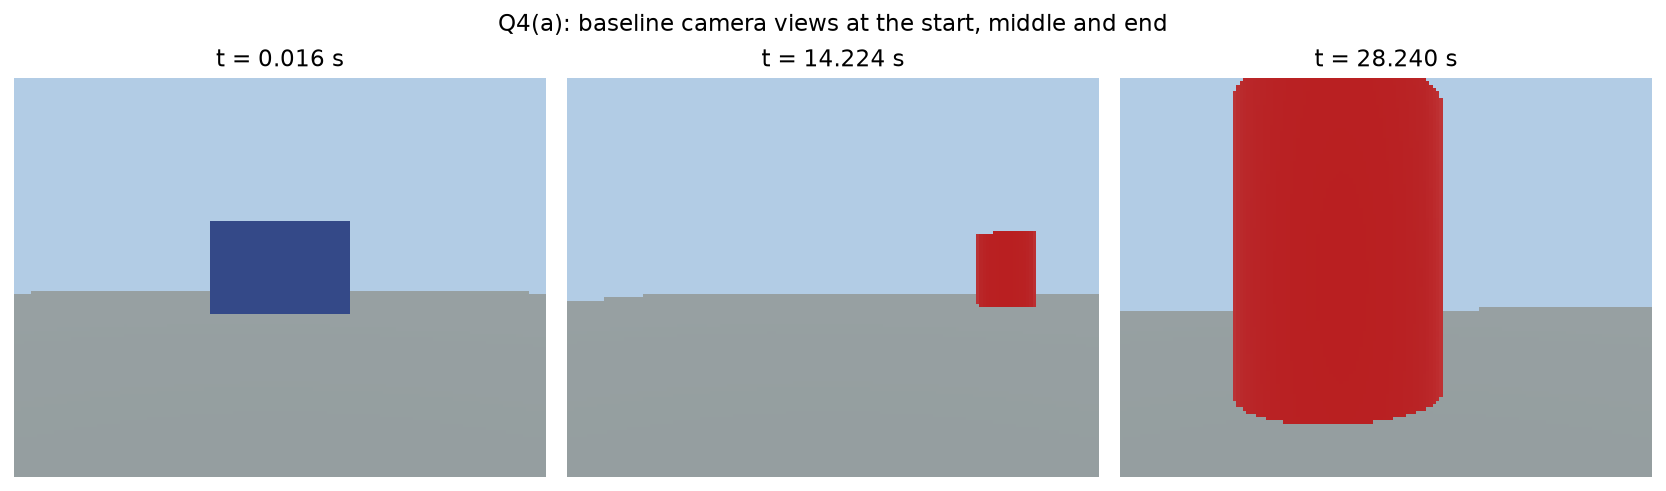

In [ ]:
# Step 4: Inspect measured camera frames from one baseline run.
q4_example = q4_runs["baseline"][0]
q4_camera_rows = q4_example["sensors"].dropna(subset=["camera_file"])
q4_selected = q4_camera_rows.iloc[[0, len(q4_camera_rows)//2, -1]]
q4_fig, q4_axes = plt.subplots(1, 3, figsize=(12, 3.6))
for q4_ax, (_, q4_row) in zip(q4_axes, q4_selected.iterrows()):
    q4_ax.imshow(plt.imread(q4_example["folder"] / q4_row["camera_file"]))
    q4_ax.set_title(f"t = {q4_row['time_s']:.3f} s")
    q4_ax.axis("off")
q4_fig.suptitle("Q4(a): baseline camera views at the start, middle and end")
q4_fig.tight_layout()
plt.show()

## (b)

### Task:
Simulate lower-slip conditions by changing friction, repeat the same goal navigation and recalculate longitudinal slip.

### Approach:
1. Increase the wheel-floor Coulomb friction coefficient from **0.12 to 1.0**, using `WorldInfo.contactProperties`.
2. Keep the robot, route, controller, start pose and seed unchanged.
3. Compare three runs per condition using one mean absolute slip value per run.

The original measurement in each condition was imported as `run_001`; this is not an additional simulation. Runs `run_002` and `run_003` were subsequently recorded separately. They are repeated executions of a deterministic setup, not independent random samples of real-world uncertainty.

In [ ]:
# Step 1: Compare all six trials without pooling unequal-length sensor logs.
for q4_case in Q4_CASES:
    for q4_run in q4_runs[q4_case]:
        assert np.isclose(q4_run["metadata"]["friction"], 0.12 if q4_case == "baseline" else 1.0)
display(q4_trial_results.round(4))
q4_successful = q4_trial_results[q4_trial_results["goal_reached"]].copy()
q4_comparison = q4_successful.groupby("condition").agg(
    successful_runs=("trial", "count"),
    mean_abs_slip_pct=("mean_abs_slip_pct", "mean"),
    sd_between_runs_pct_points=("mean_abs_slip_pct", "std"),
    mean_duration_s=("duration_s", "mean"),
    mean_distance_m=("distance_m", "mean"),
).reindex(Q4_CASES)
q4_reduction_pct = 100*(1-q4_comparison.loc["low_slip", "mean_abs_slip_pct"] / q4_comparison.loc["baseline", "mean_abs_slip_pct"])
display(q4_comparison.round(4))
print(f"Reduction in mean absolute slip: {q4_reduction_pct:.2f}%")

,condition,trial,goal_reached,duration_s,distance_m,valid_samples,mean_abs_slip_pct,median_abs_slip_pct,max_abs_slip_pct
0,baseline,run_001,True,28.352,7.2480,1576,6.7622,0.0261,586.8261
1,baseline,run_002,True,28.352,7.2480,1576,6.7622,0.0261,586.8261
2,baseline,run_003,True,28.352,7.2480,1576,6.7622,0.0261,586.8261
3,low_slip,run_001,True,27.904,7.1759,1537,0.3166,0.0259,99.9999
4,low_slip,run_002,True,27.904,7.1759,1537,0.3166,0.0259,99.9999
5,low_slip,run_003,True,27.920,7.1762,1537,0.4214,0.0259,176.7994


,successful_runs,mean_abs_slip_pct,sd_between_runs_pct_points,mean_duration_s,mean_distance_m
condition,,,,,
baseline,3,6.7622,0.0000,28.3520,7.248
low_slip,3,0.3515,0.0605,27.9093,7.176


Reduction in mean absolute slip: 94.80%


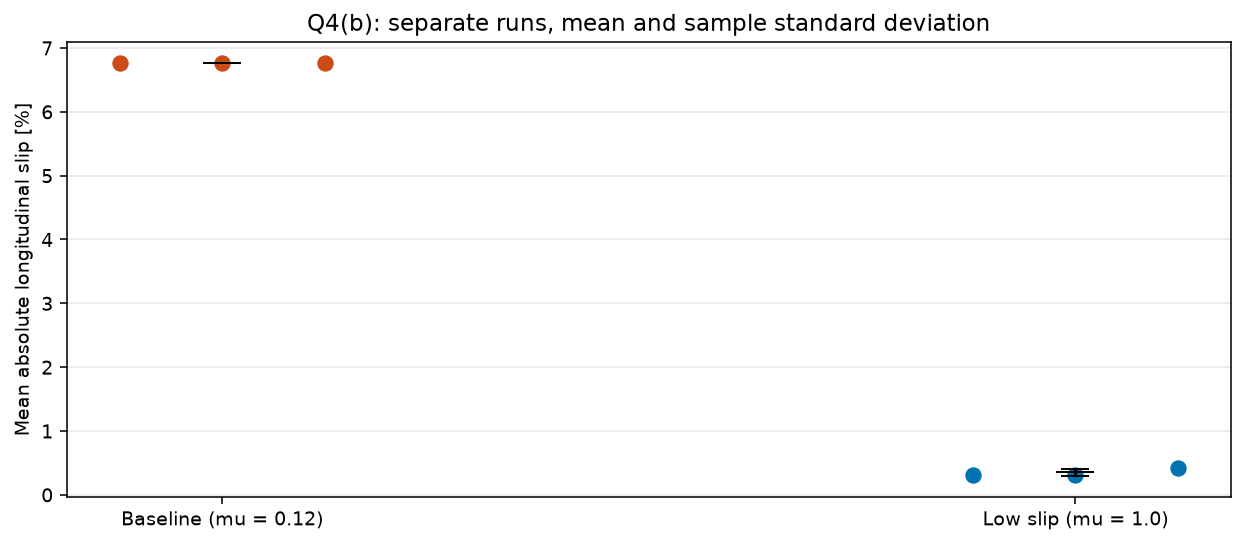

In [ ]:
# Step 2: Show separate trial means and sample standard deviation between trials.
q4_fig, q4_ax = plt.subplots(figsize=(9, 4))
for q4_i, q4_case in enumerate(Q4_CASES):
    q4_values = q4_successful.loc[q4_successful["condition"].eq(q4_case), "mean_abs_slip_pct"].to_numpy()
    q4_ax.scatter(q4_i + np.linspace(-0.12, 0.12, len(q4_values)), q4_values, color=Q4_COLORS[q4_case], s=55)
    q4_ax.errorbar(q4_i, q4_values.mean(), yerr=q4_values.std(ddof=1) if len(q4_values)>1 else 0,
                   color="black", marker="_", markersize=20, capsize=7)
q4_ax.set_xticks([0, 1], ["Baseline (mu = 0.12)", "Low slip (mu = 1.0)"])
q4_ax.set_ylabel("Mean absolute longitudinal slip [%]")
q4_ax.set_title("Q4(b): separate runs, mean and sample standard deviation")
q4_ax.grid(axis="y", alpha=0.3)
q4_fig.tight_layout()
plt.show()

### Results

All **six runs reached the defined stopping area**. Across the three run means, mean absolute slip was **6.7622% for baseline** and **0.3515% for higher friction**, a **94.80% reduction**. The sample standard deviation of the run means was **0.0000 percentage points** for baseline and **0.0605 percentage points** for higher friction.

The identical baseline means are consistent with the fixed seed and ideal sensor models. Zero observed standard deviation does not establish zero physical uncertainty. The results describe repeatability in this setup, not performance on arbitrary terrains or with realistic sensor noise.

## (c)

### Task:
Plot longitudinal slip for both cases along the robot trajectory.

### Approach:
1. Plot signed slip against travelled distance and time for all six runs.
2. Colour the measured GPS trajectories using the same colour limits and equal spatial scaling.
3. Show the lidar returns in the robot's local frame to document the sensed surroundings.

All valid slip values are retained in the time and distance plots. The trajectory colour scale is limited to $[-1,1]$ for readability, but the stored data are not clipped. Invalid near-zero-speed samples are grey.

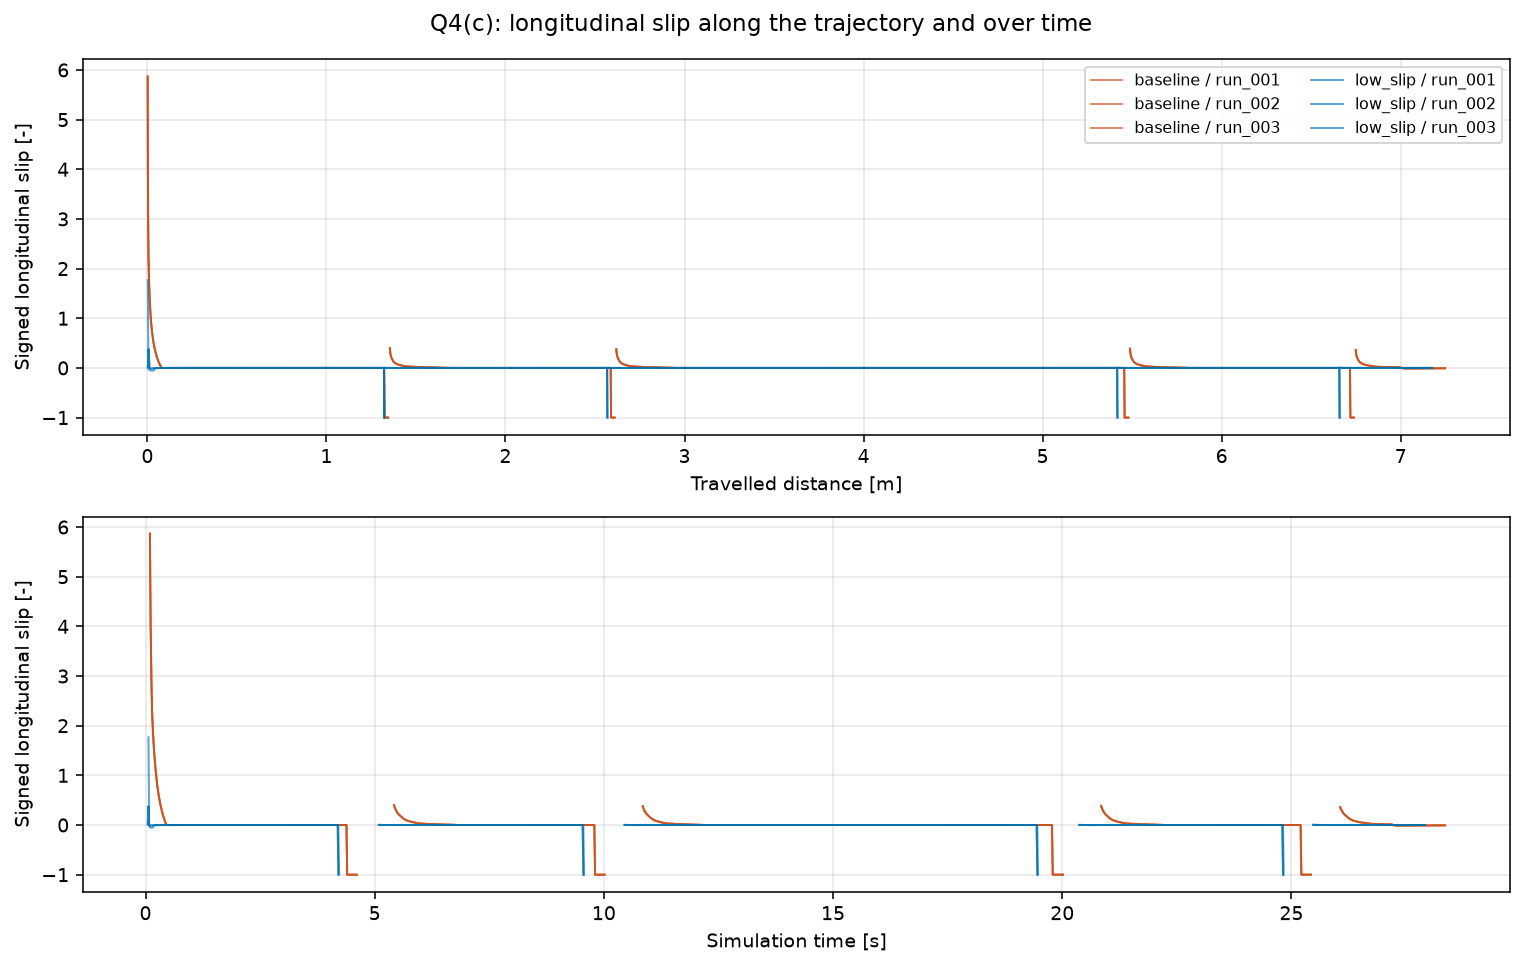

In [ ]:
# Step 1: Slip along travelled distance and over time for all runs.
q4_fig, q4_axes = plt.subplots(2, 1, figsize=(11, 7))
for q4_case in Q4_CASES:
    for q4_run in q4_runs[q4_case]:
        q4_df = q4_run["sensors"]
        q4_signed = q4_df["slip"].where(q4_df["valid_slip"].eq(1))
        q4_label = f"{q4_case} / {q4_run['id']}"
        q4_axes[0].plot(q4_df["distance_m"], q4_signed, color=Q4_COLORS[q4_case], alpha=0.65, linewidth=1, label=q4_label)
        q4_axes[1].plot(q4_df["time_s"], q4_signed, color=Q4_COLORS[q4_case], alpha=0.65, linewidth=1)
q4_axes[0].set_xlabel("Travelled distance [m]")
q4_axes[1].set_xlabel("Simulation time [s]")
for q4_ax in q4_axes:
    q4_ax.set_ylabel("Signed longitudinal slip [-]")
    q4_ax.grid(True, alpha=0.3)
q4_axes[0].legend(ncol=2, fontsize=8)
q4_fig.suptitle("Q4(c): longitudinal slip along the trajectory and over time")
q4_fig.tight_layout()
plt.show()

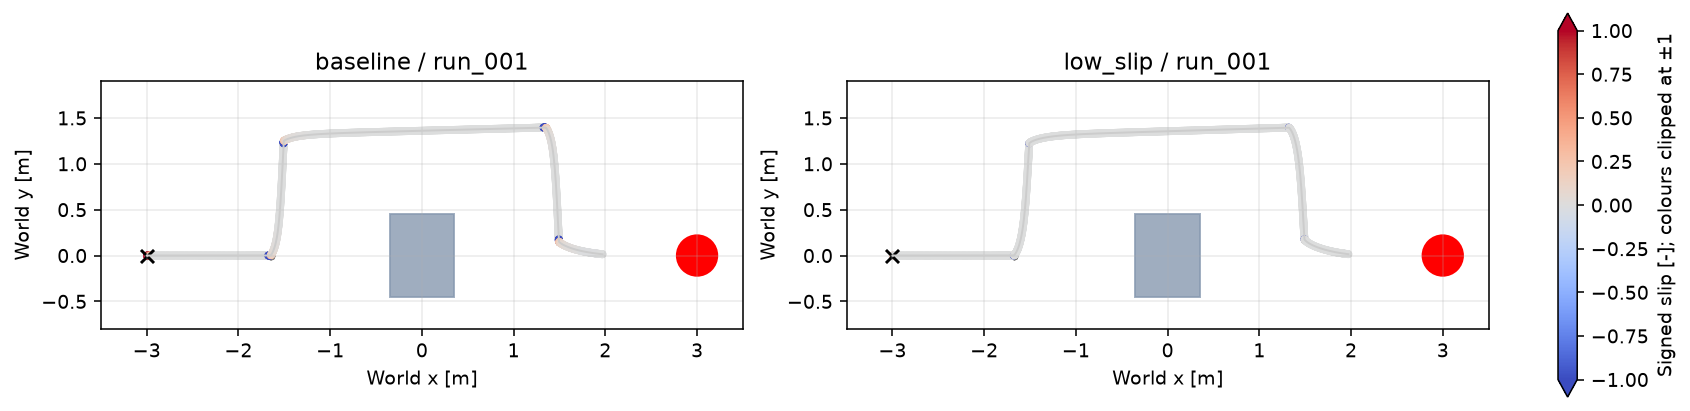

In [ ]:
# Step 2: Representative measured GPS trajectories coloured by signed slip.
# All runs appear in the time/distance plots; run_001 is shown spatially here.
q4_fig, q4_axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
q4_norm = TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1)
for q4_ax, q4_case in zip(q4_axes, Q4_CASES):
    q4_run = q4_runs[q4_case][0]
    q4_df = q4_run["sensors"]
    q4_valid = q4_df["valid_slip"].eq(1)
    q4_ax.plot(q4_df["x_m"], q4_df["y_m"], color="0.8", linewidth=1)
    q4_ax.scatter(q4_df.loc[~q4_valid, "x_m"], q4_df.loc[~q4_valid, "y_m"], color="0.5", s=7)
    q4_scatter = q4_ax.scatter(q4_df.loc[q4_valid, "x_m"], q4_df.loc[q4_valid, "y_m"],
        c=q4_df.loc[q4_valid, "slip"], cmap="coolwarm", norm=q4_norm, s=9)
    q4_ax.add_patch(Rectangle((-0.35, -0.45), 0.70, 0.90, color="#8799b0", alpha=0.8))
    q4_ax.add_patch(Circle((3, 0), 0.22, color="red"))
    q4_ax.scatter([-3], [0], c="black", marker="x", s=45)
    q4_ax.set(xlim=(-3.5, 3.5), ylim=(-0.8, 1.9), xlabel="World x [m]", ylabel="World y [m]")
    q4_ax.set_aspect("equal", adjustable="box")
    q4_ax.set_title(f"{q4_case} / {q4_run['id']}")
    q4_ax.grid(True, alpha=0.25)
q4_fig.colorbar(q4_scatter, ax=q4_axes, label="Signed slip [-]; colours clipped at ±1", extend="both", shrink=0.7)
plt.show()

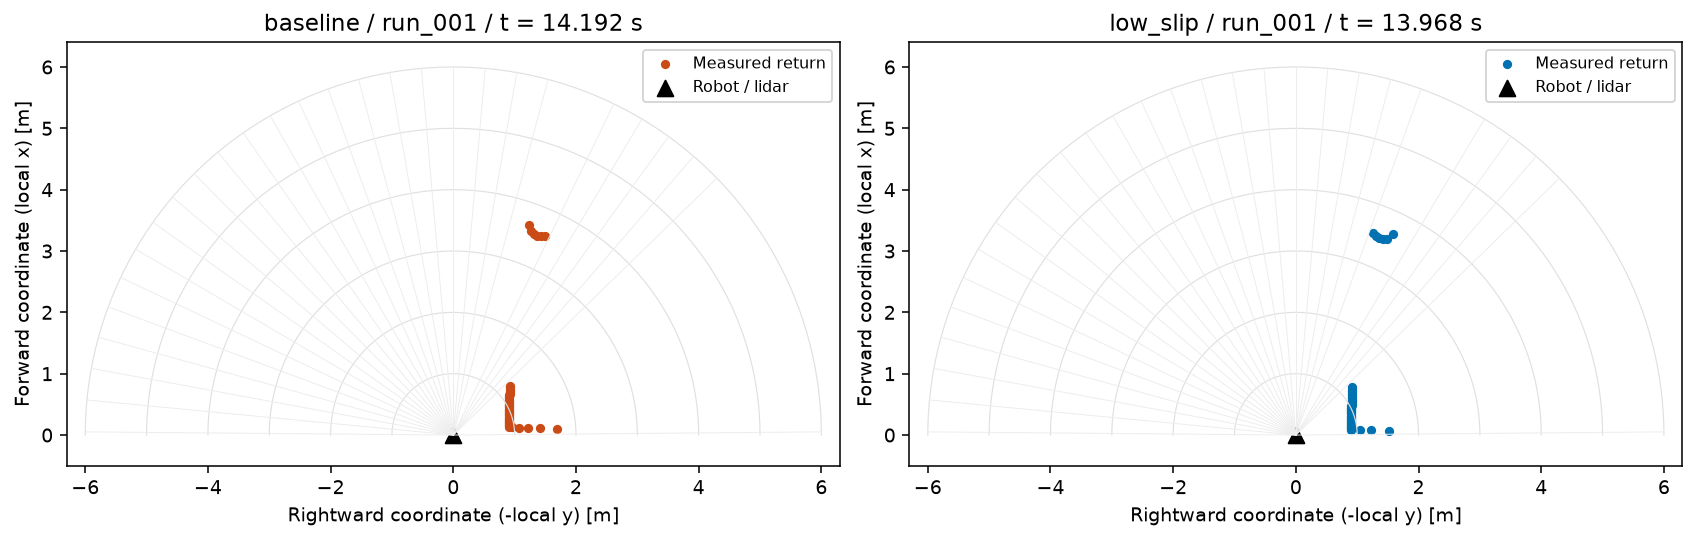

In [ ]:
# Step 3: Approximate top-down lidar reconstruction from a measured scan.
q4_fig, q4_axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for q4_ax, q4_case in zip(q4_axes, Q4_CASES):
    q4_run = q4_runs[q4_case][0]
    q4_scan = q4_run["lidar"][len(q4_run["lidar"])//2]
    q4_ranges = np.array([np.nan if v is None else v for v in q4_scan["ranges_m"]])
    q4_fov = q4_run["metadata"]["lidar_fov_rad"]
    q4_max_range = q4_run["metadata"]["lidar_max_range_m"]
    # Cylindrical projection, left-to-right ordering, approximate pixel-centre angles.
    q4_angles = q4_fov/2 - (np.arange(len(q4_ranges))+0.5)*q4_fov/len(q4_ranges)
    q4_hit = np.isfinite(q4_ranges)
    q4_forward = q4_ranges*np.cos(q4_angles)
    q4_left = q4_ranges*np.sin(q4_angles)
    q4_arc = np.linspace(-np.pi/2, np.pi/2, 200)
    for q4_radius in [1, 2, 3, 4, 5, 6]:
        q4_ax.plot(-q4_radius*np.sin(q4_arc), q4_radius*np.cos(q4_arc), color="0.88", linewidth=0.6)
    for q4_i in np.flatnonzero(~q4_hit)[::5]:
        q4_ax.plot([0, -q4_max_range*np.sin(q4_angles[q4_i])],
                   [0, q4_max_range*np.cos(q4_angles[q4_i])], color="0.93", linewidth=0.5)
    q4_ax.scatter(-q4_left[q4_hit], q4_forward[q4_hit], color=Q4_COLORS[q4_case], s=14, label="Measured return")
    q4_ax.scatter([0], [0], c="black", marker="^", s=65, label="Robot / lidar")
    q4_ax.set(xlim=(-6.3, 6.3), ylim=(-0.5, 6.4), xlabel="Rightward coordinate (-local y) [m]", ylabel="Forward coordinate (local x) [m]")
    q4_ax.set_aspect("equal", adjustable="box")
    q4_ax.set_title(f"{q4_case} / {q4_run['id']} / t = {q4_scan['time_s']:.3f} s")
    q4_ax.legend(fontsize=8)
plt.show()

### Interpretation and limitations

The largest baseline peak occurs during initial acceleration. In run_001, at 0.096 s, $v_{enc}\approx0.3499$ m/s and $v_x\approx0.05094$ m/s give $s_{long}\approx5.8683$ (586.83%). This is just above the speed-validity threshold, so the small denominator amplifies the ratio. Negative slip can occur during deceleration or a turn while the robot still moves forward but the mean wheel-based forward speed falls.

The median absolute slip is small in both conditions. The differences in the means are mainly due to transient events. The results therefore support reduced **mean absolute slip**, not a claim that every point along the route improves by 94.80%.

The lidar view is an approximate reconstruction in each sensor's **local frame**, not a global map or directly recorded point cloud. The two panels have equal length scales but show different robot poses and slightly different times. Coloured points are measured returns; faint rays indicate selected directions without a valid return and do not represent obstacles at 6 m.

Camera images were saved every 12 steps (5.21 Hz), while other sensors were saved at 62.5 Hz. The accelerometer includes gravity, so its z component is approximately 9.81 m/s² when level and stationary. No IMU/GPS fusion filter was implemented. Collision contacts and forces were not logged, so lidar clearance alone cannot prove zero physical contact. The user observed the robot passing the box and stopping in front of the cylinder; all six logs satisfy the implemented stopping criterion.

### Conclusion

The robot navigated around the predefined obstacle and reached the stopping area in both friction conditions. All requested sensor types were recorded. Raising friction from 0.12 to 1.0 reduced the average of the three run-level mean absolute slips from 6.7622% to 0.3515%. The logs, camera frames, controller and world files are supplied so the calculations can be checked.

### Webots controller source and reproducibility

Open `Q4_webots/worlds/baseline.wbt` or `low_slip.wbt` in Webots. The controller is `controllers/navigation/navigation.py`; it imports the companion `trial_store.py` from the project root. Each run has its own `results/runs/<condition>/run_NNN` directory. Incomplete runs are excluded from the analysis.

The next cell **displays the source only**. It does not import the Webots API, execute the controller, write measurements or start a simulation from Jupyter. Reset the simulation in Webots between new runs, then re-run the Q4 analysis cells.

In [ ]:
# Display the actual controller and its required storage helper.
for q4_source_name in ["controllers/navigation/navigation.py", "trial_store.py"]:
    print("Webots source:", q4_source_name)
    display(Code(filename=str(Q4_PROJECT / q4_source_name), language="python"))

Webots source: controllers/navigation/navigation.py


"""Q4: identical waypoint navigation in both friction conditions."""
from controller import Supervisor
from pathlib import Path
import csv, json, math, os, sys, hashlib
PROJECT=Path(__file__).resolve().parents[2]
sys.path.insert(0,str(PROJECT))
from trial_store import allocate,write_json
r=Supervisor(); step=int(r.getBasicTimeStep()); dt=step/1000
case=r.getCustomData(); out=allocate(PROJECT,case)
print('Recording independent trial:',out,flush=True)
self=r.getSelf()
# A saved world may contain the final pose of the previous run.
# Reset the experiment before collecting any measurements.
self.getField('translation').setSFVec3f([-3.0, 0.0, 0.101])
self.getField('rotation').setSFRotation([0.0, 0.0, 1.0, 0.0])
self.resetPhysics()
start_sim=r.getTime()
motors=[r.getDevice(s+' motor') for s in ('left','right')]
enc=[r.getDevice(s+' encoder') for s in ('left','right')]
for m in motors: m.setPosition(float('inf')); m.setVelocity(0)
for e in enc: e.enable(step)
dev={s:r.getDevice(s) for s in ('gps','accelerometer','gyro','imu','camera','lidar')}
for d in dev.values(): d.enable(step)
metadata=json.loads((out/'metadata.json').read_text())
metadata.update({'basic_time_step_ms':step,'camera_stride':12,
 'friction':r.getFromDef('TRACTION').getField('coulombFriction').getMFFloat(0),
 'lidar_fov_rad':dev['lidar'].getFov(),'lidar_max_range_m':dev['lidar'].getMaxRange(),
 'lidar_projection':'cylindrical','random_seed':42,
 'wheel_radius_m':0.1,'track_width_m':0.31,'slip_min_speed_m_s':0.05,
 'controller_sha256':hashlib.sha256(Path(__file__).read_bytes()).hexdigest(),
 'start_position_m':[-3.0,0.0,0.101],
 'waypoints_m':[[-1.5,0],[-1.5,1.4],[1.5,1.4],[1.5,0],[2.15,0]]})
write_json(out/'metadata.json',metadata)
# Known goal position is allowed; the camera is recorded, not used for recognition.
waypoints=[(-1.5,0),(-1.5,1.4),(1.5,1.4),(1.5,0),(2.15,0)]
avoid_until=0.0; avoid_turn=1.0
k=0; previous=None; distance=0; lastxy=None; reached=False; min_clear=99
f=open(out/'sensors.csv','w',newline=''); w=csv.writer(f)
w.writerow(['time_s','x_m','y_m','distance_m','left_rad','right_rad','omega_left','omega_right','v_enc_m_s','vx_m_s','slip','valid_slip','ax','ay','az','gx','gy','gz','roll','pitch','yaw','gps_z','lidar_min_m','camera_file'])
l=open(out/'lidar.jsonl','w'); count=0
while r.step(step)!=-1:
 t=r.getTime()-start_sim; xyz=dev['gps'].getValues(); x,y=xyz[:2]; ori=self.getOrientation()
 yaw=math.atan2(ori[3],ori[0]); velocity=self.getVelocity()
 vx=velocity[0]*ori[0]+velocity[1]*ori[3]+velocity[2]*ori[6]
 angles=[e.getValue() for e in enc]
 omega=[(angles[i]-previous[i])/dt if previous else 0 for i in range(2)]; previous=angles
 venc=0.1*sum(omega)/2
 valid=abs(vx)>=0.05; slip=(venc-vx)/vx if valid else ''
 if lastxy: distance+=math.hypot(x-lastxy[0],y-lastxy[1])
 lastxy=(x,y)
 ranges=dev['lidar'].getRangeImage(); finite=[v for v in ranges if math.isfinite(v)]
 nearest=min(finite,default=6); min_clear=min(min_clear,nearest)
 image=''
 if count%12==0:
  image=f'camera/{count:06d}.png'; dev['camera'].saveImage(str(out/image),100)
 w.writerow([t,x,y,distance,*angles,*omega,venc,vx,slip,int(valid),*dev['accelerometer'].getValues(),*dev['gyro'].getValues(),*dev['imu'].getRollPitchYaw(),xyz[2],nearest,image])
 l.write(json.dumps({'time_s':t,'ranges_m':[v if math.isfinite(v) else None for v in ranges]})+'\n')
 if count%60==0: f.flush(); l.flush()
 count+=1
 tx,ty=waypoints[k]; dist=math.hypot(tx-x,ty-y)
 if dist<0.18:
  k+=1
  if k==len(waypoints): reached=True; break
  tx,ty=waypoints[k]
 error=math.atan2(math.sin(math.atan2(ty-y,tx-x)-yaw),math.cos(math.atan2(ty-y,tx-x)-yaw))
 turn=max(-1.0,min(1.0,2.0*error)); speed=min(0.35,0.8*dist)*max(0,1-abs(error)/0.8)
 front=min([v for v in ranges[70:111] if math.isfinite(v)],default=6)
 # Latch the chosen escape turn to prevent left/right oscillation.
 if front<0.65 and t>=avoid_until:
  left=sum(min(v,6) for v in ranges[:60]); right=sum(min(v,6) for v in ranges[-60:])
  avoid_turn=1.0 if left>=right else -1.

Webots source: trial_store.py


"""Safe storage and discovery of independent Webots trials (standard library)."""
from pathlib import Path
from datetime import datetime, timezone
import json, csv, shutil, statistics, hashlib
CASES=('baseline','low_slip')
def write_json(path,value):
    path=Path(path); temp=path.with_suffix(path.suffix+'.tmp')
    temp.write_text(json.dumps(value,indent=2,allow_nan=False),encoding='utf-8');temp.replace(path)
def allocate(root,case):
    if case not in CASES:raise ValueError('Unknown experiment condition: '+case)
    parent=Path(root)/'results'/'runs'/case;parent.mkdir(parents=True,exist_ok=True)
    n=1
    while True:
        path=parent/f'run_{n:03d}'
        try:path.mkdir();break
        except FileExistsError:n+=1
    (path/'camera').mkdir()
    write_json(path/'metadata.json',{'case':case,'trial_id':path.name,'status':'running','started_utc':datetime.now(timezone.utc).isoformat(),'origin':'new_simulation'})
    return path
def completed(root,case):
    parent=Path(root)/'results'/'runs'/case
    return sorted(p for p in parent.glob('run_*') if (p/'summary.json').is_file() and (p/'sensors.csv').is_file() and (p/'lidar.jsonl').is_file())
def successful(root,case):
    return [p for p in completed(root,case) if json.loads((p/'summary.json').read_text())['goal_reached']]
def latest(root,case):
    paths=completed(root,case)
    if paths:return paths[-1]
    old=Path(root)/'results'/case
    if (old/'summary.json').exists() and (old/'sensors.csv').exists():return old
    raise FileNotFoundError(f'No completed trial for {case}. Run that world first.')
def migrate_legacy(root):
    """Import the existing trial once; it is not counted as a new simulation."""
    root=Path(root)
    for case in CASES:
        old=root/'results'/case;parent=root/'results'/'runs'/case
        if parent.exists() and any(parent.glob('run_*')):continue
        if not all((old/name).exists() for name in ('summary.json','sensors.csv','lidar.jsonl')):continue
        dest=allocate(root,case)
        for name in ('summary.json','sensors.csv','lidar.jsonl'):shutil.copy2(old/name,dest/name)
        with (old/'sensors.csv').open(newline='') as f:
            for row in csv.DictReader(f):
                if row['camera_file']:
                    rel=Path(row['camera_file'])
                    if rel.is_absolute() or '..' in rel.parts:raise ValueError('Unsafe image reference')
                    shutil.copy2(old/rel,dest/rel)
        write_json(dest/'metadata.json',{'case':case,'trial_id':dest.name,'status':'complete','origin':'imported_existing_measurements','imported_utc':datetime.now(timezone.utc).isoformat(),'note':'Original measured trial, not a new repetition. Original logs retained.','basic_time_step_ms':16,'camera_stride':12,'friction':0.12 if case=='baseline' else 1.0,'random_seed':42,'lidar_fov_rad':3.14159,'lidar_max_range_m':6,'lidar_projection':'cylindrical'})
def metrics(path):
    path=Path(path)
    with (path/'sensors.csv').open(newline='') as f:rows=list(csv.DictReader(f))
    values=[abs(float(r['slip'])) for r in rows if r['valid_slip']=='1' and r['slip']]
    summary=json.loads((path/'summary.json').read_text())
    return {**summary,'trial_id':path.name,'valid_slip_samples':len(values),'total_samples':len(rows),'mean_abs_slip':statistics.mean(values) if values else None,'median_abs_slip':statistics.median(values) if values else None,'max_abs_slip':max(values) if values else None}
if __name__=='__main__':
    root=Path(__file__).resolve().parent;migrate_legacy(root)
    for c in CASES:print(c,len(successful(root,c)),'successful trials')

### References

- Cyberbotics, [Webots R2025a ContactProperties](https://github.com/cyberbotics/webots/blob/R2025a/docs/reference/contactproperties.md): wheel-floor friction.
- Cyberbotics, [Webots R2025a Supervisor](https://github.com/cyberbotics/webots/blob/R2025a/docs/reference/supervisor.md): true velocity and robot orientation.
- Cyberbotics, [Webots R2025a Lidar](https://github.com/cyberbotics/webots/blob/R2025a/docs/reference/lidar.md): range-image ordering and cylindrical projection.